# Proyecto 2: Fine-tuning para tareas de PLN

Curso de Procesamiento de Lenguaje Natural, Universidad de Antioquia.

## Introducción

En este proyecto hago fine-tuning de tres modelos preentrenados de Hugging Face, uno para cada tipo de problema de PLN que pide el enunciado.

Un modelo preentrenado ya aprendió bastante sobre el idioma porque se entrenó con grandes cantidades de texto sin etiquetas, con tareas como adivinar palabras tapadas o reconstruir texto dañado. Hacer fine-tuning es seguir entrenando ese modelo con un dataset etiquetado mucho más pequeño para que aprenda una tarea concreta. En clasificación y en etiquetado se le agrega una capa de salida nueva para la tarea; en seq2seq se reutiliza la parte que genera texto, que ya viene en el modelo. Se entrenan todos los pesos con un learning rate bajo para no dañar lo que el modelo ya sabía.

La ventaja es que no hay que aprender el idioma desde cero. Con unos miles de ejemplos y minutos u horas de GPU se llega a resultados que entrenando desde cero pedirían muchos más datos y tiempo.

| Tarea | Tipo de problema | Dataset | Idioma | Modelo | Métrica principal |
|---|---|---|---|---|---|
| 1 | Clasificación de secuencias: emoción de un tuit (6 clases) | `dair-ai/emotion` | inglés | `distilbert/distilbert-base-uncased` | F1 macro |
| 2 | Etiquetado de secuencias: reconocimiento de entidades (NER) | `BramVanroy/conll2002` (config `es`) | español | `dccuchile/bert-base-spanish-wwm-cased` (BETO) | F1 de seqeval |
| 3 | Sequence-to-sequence: resumen de diálogos | `knkarthick/dialogsum` | inglés | `facebook/bart-base` | ROUGE |

El notebook está organizado así:

- Sección 0: configuración del entorno (instalación en Colab, login en Hugging Face, dispositivo, semilla y funciones comunes).
- Tareas 1, 2 y 3, cada una con las mismas cinco partes: x.1 descripción del dataset, x.2 análisis exploratorio, x.3 búsqueda de hiperparámetros sobre una muestra, x.4 entrenamiento con la data completa y x.5 evaluación del mejor modelo.
- Conclusiones.

Cada tarea empieza con una celda de constantes (dataset y modelo) y se puede correr sola, siempre que antes se haya corrido la sección 0. El entrenamiento lo hago en Colab con una GPU T4. Por qué escogí estos datasets y modelos está en `docs/seleccion_datasets.md` del repositorio.

## 0. Configuración del entorno

El notebook corre igual en Colab y en local. Para correrlo:

- En Colab: Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU T4. El token de Hugging Face va en los Secrets de Colab con el nombre `HF_TOKEN`, y los resultados (modelos, tablas y figuras) quedan en Google Drive.
- En local: `uv sync` en la raíz del repo, el kernel `proyecto2-nlp` y el token en el archivo `.env`.

La primera celda detecta dónde está corriendo. En Colab instala lo que falta con las mismas versiones del `uv.lock` del repo y deja el torch que trae Colab, que ya viene con CUDA. En local no instala nada, porque las dependencias salen de `uv sync`. La segunda celda monta Drive si está en Colab, lee el token de Hugging Face, escoge el dispositivo y fija la semilla. La tercera tiene funciones que uso en los tres análisis exploratorios y la cuarta, lo que comparten los tres entrenamientos.

In [1]:
# Detección del entorno e instalación (solo en Colab)
import importlib.metadata as md
import os
import re
import subprocess
import sys
import tempfile

IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

# Mismas versiones del uv.lock. Si se actualiza el lock hay que cambiarlas aquí;
# scripts/check_env.py avisa cuando no coinciden.
COLAB_PINS = {
    "transformers": "5.23.0",
    "tokenizers": "0.23.3",
    "huggingface-hub": "2.4.0",
    "datasets": "5.2.0",
    "evaluate": "0.4.6",
    "accelerate": "1.16.0",
    "seqeval": "1.2.2",
    "sacrebleu": "2.6.0",
    "rouge-score": "0.1.2",
}


def _norm(nombre):
    return re.sub(r"[-_.]+", "-", nombre).lower()


def _instaladas():
    return {_norm(d.metadata["Name"]): d.version for d in md.distributions()}


if IN_COLAB:
    antes = _instaladas()
    pendientes = [f"{p}=={v}" for p, v in COLAB_PINS.items() if antes.get(_norm(p)) != v]
    assert "torch" in antes, "Colab debería traer torch preinstalado"
    if pendientes:
        # El constraint deja torch exactamente como viene en Colab: si algo pidiera
        # otra versión, pip falla en vez de reinstalarlo.
        with tempfile.NamedTemporaryFile("w", suffix=".txt", delete=False) as f:
            f.write(f"torch=={antes['torch']}\n")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "-c", f.name, *pendientes],
            check=True,
        )
        despues = _instaladas()
        assert despues["torch"] == antes["torch"], "pip cambió la versión de torch"
        cambiadas = {p for p, v in despues.items() if antes.get(p) != v}
        # Si alguna librería actualizada ya estaba importada, hay que reiniciar la sesión
        cargadas = sorted(
            mod
            for mod, dists in md.packages_distributions().items()
            if mod in sys.modules and any(_norm(d) in cambiadas for d in dists)
        )
        if cargadas:
            raise SystemExit(
                f"Se actualizaron librerías que ya estaban cargadas ({', '.join(cargadas)}). "
                "Entorno de ejecución > Reiniciar sesión y vuelve a correr el notebook desde arriba."
            )
    for p in ["torch", *COLAB_PINS]:
        print(f"{p:<16} {md.version(p)}")
else:
    print("Entorno local: las dependencias vienen de uv.lock (uv sync). No se instala nada.")

torch            2.14.1+cu130
transformers     5.23.0
tokenizers       0.23.3
huggingface-hub  2.4.0
datasets         5.2.0
evaluate         0.4.6
accelerate       1.16.0
seqeval          1.2.2
sacrebleu        2.6.0
rouge-score      0.1.2


In [2]:
# Configuración general: Drive, token de Hugging Face, dispositivo, semilla y rutas
import logging
import platform
from pathlib import Path

# En Mac, las operaciones que MPS no soporta caen a CPU en vez de fallar.
# Tiene que definirse antes de importar torch.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import torch
import transformers
import datasets
from huggingface_hub import whoami

SEED = 42

if IN_COLAB:
    from google.colab import drive, userdata

    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/proyecto2-nlp/outputs")
    try:
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception as e:  # el secret no existe o el notebook no tiene acceso
        HF_TOKEN = None
        print(f"No se pudo leer HF_TOKEN de los Secrets de Colab ({type(e).__name__}).")
else:
    from dotenv import load_dotenv

    # Raíz del repo: la carpeta que tiene pyproject.toml (el notebook vive en notebooks/)
    PROJECT_ROOT = next(
        (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()),
        Path.cwd(),
    )
    load_dotenv(PROJECT_ROOT / ".env")
    OUTPUT_DIR = PROJECT_ROOT / "outputs"
    HF_TOKEN = os.getenv("HF_TOKEN") or None

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Token de Hugging Face, sin mostrarlo. huggingface_hub lo lee de la variable de entorno
# HF_TOKEN, así que no uso login(), que además copiaría el token a ~/.cache/huggingface.
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    try:
        whoami()  # falla si el token no es válido
        print("Token de Hugging Face: OK")
    except Exception as e:
        print(f"El token de Hugging Face no funcionó ({type(e).__name__}). Revisa que sea válido.")
else:
    print("Sin HF_TOKEN: se sigue sin login (los modelos y datasets públicos funcionan igual).")
    # Sin token, el Hub responde con un aviso de "unauthenticated requests" en la primera
    # descarga. Es lo mismo que dice el print de arriba, así que filtro solo ese mensaje.
    logging.getLogger("huggingface_hub.utils._http").addFilter(
        lambda registro: "unauthenticated requests" not in registro.getMessage()
    )

# Dispositivo
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    detalle = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    detalle = "Apple Silicon (MPS)"
else:
    DEVICE = torch.device("cpu")
    detalle = platform.processor() or "CPU"
if IN_COLAB and DEVICE.type != "cuda":
    print("OJO: no hay GPU. Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU.")

# Semilla (random, numpy y torch)
transformers.set_seed(SEED)

print(f"Entorno:      {'Colab' if IN_COLAB else 'local'}")
print(f"Python:       {platform.python_version()}")
print(f"torch:        {torch.__version__}")
print(f"transformers: {transformers.__version__}")
print(f"datasets:     {datasets.__version__}")
print(f"Dispositivo:  {DEVICE} ({detalle})")
print(f"Semilla:      {SEED}")
# En local muestro la ruta relativa a la raíz del repo, para que mi ruta no quede en las salidas
print(f"OUTPUT_DIR:   {OUTPUT_DIR if IN_COLAB else OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Mounted at /content/drive
No se pudo leer HF_TOKEN de los Secrets de Colab (SecretNotFoundError).
Sin HF_TOKEN: se sigue sin login (los modelos y datasets públicos funcionan igual).
Entorno:      Colab
Python:       3.13.16
torch:        2.14.1+cu130
transformers: 5.23.0
datasets:     5.2.0
Dispositivo:  cuda (Tesla T4)
Semilla:      42
OUTPUT_DIR:   /content/drive/MyDrive/proyecto2-nlp/outputs


In [3]:
# Utilidades que uso en los análisis exploratorios de las tres tareas
from collections import Counter
import textwrap

import datasets
import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Sin barras de progreso de descarga: ensucian las salidas guardadas del notebook
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 50)

# Las figuras también quedan guardadas para el informe y el video
FIG_DIR = OUTPUT_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def percentil(x, p):
    """Percentil p redondeado hacia arriba."""
    return int(np.ceil(np.percentile(np.asarray(x), p)))


def resumen_longitudes(longitudes):
    """Media, percentiles y máximo de una serie de longitudes."""
    x = np.asarray(longitudes)
    return {
        "media": round(float(x.mean()), 1),
        "p50": percentil(x, 50),
        "p95": percentil(x, 95),
        "p99": percentil(x, 99),
        "máx": int(x.max()),
    }


def tabla_longitudes(dfs, columnas):
    """Resumen de longitudes por split y columna. dfs es un dict split -> DataFrame."""
    filas = {(split, col): resumen_longitudes(df[col]) for split, df in dfs.items() for col in columnas}
    return pd.DataFrame.from_dict(filas, orient="index")


def marcar_percentiles(ax, x):
    """Líneas verticales en el p95 y el p99 de x."""
    for p, estilo in [(95, "--"), (99, ":")]:
        ax.axvline(percentil(x, p), color="black", linestyle=estilo, label=f"p{p} = {percentil(x, p)}")
    ax.legend()


def guardar(fig, nombre, carpeta=FIG_DIR):
    fig.savefig(Path(carpeta) / f"{nombre}.png", dpi=120, bbox_inches="tight")

La cuarta celda tiene lo que comparten los entrenamientos de las tres tareas:

- Modo completo y modo rápido: si hay GPU CUDA (Colab con la T4), el notebook entrena de verdad. Si no hay, como en mi Mac, hace una prueba rápida con unos cientos de ejemplos para comprobar que el código corre de punta a punta. Los números de esa prueba no sirven como resultado, y todo lo que guarda va a `OUTPUT_DIR/prueba_rapida`, separado de los resultados reales.
- Guardar y no repetir: cada paso pesado guarda lo que produce en la carpeta de su tarea (por ejemplo `OUTPUT_DIR/tarea1`), que en Colab queda en Drive. Si el archivo ya existe, la celda lo carga en vez de entrenar otra vez, salvo que ponga `REENTRENAR = True` en la configuración de la tarea. Así no pierdo un entrenamiento si Colab se desconecta o si vuelvo a correr el notebook para regenerar una gráfica. El entrenamiento completo y el test guardan además el learning rate y las épocas con que se hicieron, y `cargar_si_vigente()` los compara con los de ahora: si la búsqueda da otro ganador o cambio las épocas, esos pasos se rehacen solos, sin tocar `REENTRENAR`.
- Checkpoints: en la búsqueda de learning rate no guardo ninguno. En el entrenamiento completo el Trainer guarda un checkpoint solo cuando mejora la métrica de validación, y solo con los pesos (sin el estado del optimizador). En Colab esos checkpoints van al disco local de la máquina; a Drive solo va el mejor modelo, y los checkpoints se borran al final. Así no lleno Drive, donde lo que se borra desde Colab puede quedar en la papelera.
- Registro: no uso barras de progreso porque ensucian el notebook guardado. En su lugar imprimo una línea por época con la loss y las métricas. De cada corrida guardo el tiempo de entrenamiento y las muestras por segundo, para recalcular los tiempos estimados de las tareas 2 y 3.
- Opciones comunes de `TrainingArguments`: fp16 solo con CUDA (la T4 no tiene bf16), `report_to="none"` para no mandar métricas a servicios externos, la misma semilla en todas las corridas, batch 16, warmup lineal en el primer 10 % de los pasos y weight decay de 0.01 (el valor del paper de BERT). Cada tarea cambia lo que necesite.

In [ ]:
# Utilidades de entrenamiento para las tres tareas
import gc
import json
import shutil

# En Mac, torch avisa al importar el Trainer que no soporta redirecciones en entrenamiento
# distribuido. Aquí no se usa, así que silencio solo ese aviso.
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import transformers
from transformers import PrinterCallback, Trainer, TrainerCallback, TrainingArguments

# Sin barras de progreso al cargar y guardar modelos
transformers.logging.disable_progress_bar()

# Al crear un modelo con una cabeza nueva, transformers imprime un "LOAD REPORT" en cada
# corrida: MISSING son las capas de la cabeza, que empiezan al azar, y UNEXPECTED la cabeza
# de preentrenamiento que no se usa. Es lo esperado en un fine-tuning, así que lo filtro.
# Los errores de carga de verdad (tamaños que no cuadran) igual lanzan una excepción.
logging.getLogger("transformers.modeling_utils").addFilter(lambda registro: "LOAD REPORT" not in registro.getMessage())

# Con GPU CUDA (Colab) corre el modo completo. Sin ella (mi Mac) corre una prueba rápida
# con muy pocos ejemplos, solo para ver que el código funciona de punta a punta.
MODO_RAPIDO = not torch.cuda.is_available()

# La prueba rápida guarda en otra carpeta para no mezclarse con los resultados de verdad
RESULTADOS_DIR = OUTPUT_DIR / "prueba_rapida" if MODO_RAPIDO else OUTPUT_DIR
FIG_ENTRENAMIENTO_DIR = RESULTADOS_DIR / "figuras"
FIG_ENTRENAMIENTO_DIR.mkdir(parents=True, exist_ok=True)

# Los checkpoints intermedios van al disco local de Colab y no a Drive
CHECKPOINTS_DIR = Path("/content/checkpoints") if IN_COLAB else RESULTADOS_DIR / "checkpoints"


def ruta(p):
    """Ruta para imprimir, relativa a OUTPUT_DIR (así no salen rutas locales)."""
    p = Path(p)
    return "OUTPUT_DIR" if p == OUTPUT_DIR else f"OUTPUT_DIR/{p.relative_to(OUTPUT_DIR).as_posix()}"


def recortar(ds, n):
    """En la prueba rápida devuelve n ejemplos al azar; en el modo completo, todo el split."""
    return ds.shuffle(seed=SEED).select(range(min(n, len(ds)))) if MODO_RAPIDO else ds


def titulo(texto):
    """Título de figura, marcado cuando sale de la prueba rápida."""
    return f"[PRUEBA RÁPIDA] {texto}" if MODO_RAPIDO else texto


def aviso_prueba_rapida():
    if MODO_RAPIDO:
        print("PRUEBA RÁPIDA: estos números salen de muy pocos ejemplos y NO sirven como resultado.\n")


def argumentos(carpeta, **cambios):
    """TrainingArguments que comparten las tres tareas. Cada tarea cambia lo que necesite."""
    base = dict(
        output_dir=str(carpeta),
        eval_strategy="epoch",
        logging_strategy="epoch",  # la loss de train queda promediada por época
        save_strategy="no",
        per_device_train_batch_size=16,
        per_device_eval_batch_size=64,
        warmup_steps=0.1,  # un float menor que 1 es la fracción de pasos con warmup
        weight_decay=0.01,
        fp16=torch.cuda.is_available(),  # la T4 no tiene bf16; sin CUDA, fp32
        report_to="none",
        disable_tqdm=True,  # sin barras: LineaPorEpoca imprime una línea por época
        dataloader_pin_memory=torch.cuda.is_available(),  # solo sirve con CUDA; en MPS avisa
        seed=SEED,
    )
    return TrainingArguments(**(base | cambios))


def metricas_eval(registro):
    """Métricas de validación de un registro del Trainer, sin los tiempos y sin el prefijo eval_."""
    return {
        ("loss_val" if k == "eval_loss" else k.removeprefix("eval_")): v
        for k, v in registro.items()
        if k.startswith("eval_") and not k.endswith(("runtime", "per_second"))
    }


class LineaPorEpoca(TrainerCallback):
    """Imprime una línea por época con la loss de train y las métricas de validación."""

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        loss_train = next((h["loss"] for h in reversed(state.log_history) if "loss" in h), float("nan"))
        valores = "  ".join(f"{k} {v:.4f}" for k, v in metricas_eval(metrics).items())
        print(f"época {state.epoch:.0f}  loss_train {loss_train:.4f}  {valores}")


def historial_por_epoca(log_history):
    """Una fila por época: loss de train y métricas de validación."""
    loss_train = {round(h["epoch"]): h["loss"] for h in log_history if "loss" in h}
    return pd.DataFrame([
        {"época": round(h["epoch"]), "loss_train": loss_train.get(round(h["epoch"])), **metricas_eval(h)}
        for h in log_history
        if "eval_loss" in h
    ])


def entrenar(trainer):
    """Entrena con una línea por época. Devuelve el historial y la velocidad."""
    trainer.remove_callback(PrinterCallback)
    trainer.add_callback(LineaPorEpoca)
    salida = trainer.train()
    velocidad = {
        # el tiempo incluye la evaluación al final de cada época
        "segundos_entrenamiento": round(salida.metrics["train_runtime"], 1),
        "muestras_por_segundo": round(salida.metrics["train_samples_per_second"], 1),
    }
    print(f"Tiempo: {velocidad['segundos_entrenamiento']} s ({velocidad['muestras_por_segundo']} muestras/s)")
    return historial_por_epoca(trainer.state.log_history), velocidad


def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()


def guardar_json(datos, archivo):
    Path(archivo).write_text(json.dumps(datos, indent=2, ensure_ascii=False), encoding="utf-8")


def leer_json(archivo):
    return json.loads(Path(archivo).read_text(encoding="utf-8"))


def cargar_si_vigente(archivo, config, reentrenar):
    """Lee un JSON guardado si todavía sirve. Si no sirve, devuelve None para que la celda rehaga ese paso.

    No sirve si se pidió reentrenar, si el archivo no existe o si se hizo con otra config, por ejemplo
    con un learning rate distinto al que da ahora la búsqueda. config es un dict como
    {"learning_rate": 5e-5, "epocas": 3}, con claves que el JSON guardado también tiene.
    """
    archivo = Path(archivo)
    if reentrenar or not archivo.exists():
        return None
    guardado = leer_json(archivo)
    distintos = [k for k, v in config.items() if guardado.get(k) != v]
    if distintos:
        texto = lambda v: f"{v:g}" if isinstance(v, float) else str(v)
        detalle = "; ".join(f"{k}: guardado {texto(guardado.get(k, 'sin dato'))}, ahora {texto(config[k])}" for k in distintos)
        print(f"{ruta(archivo)} no corresponde a lo de ahora ({detalle}). Lo hago de nuevo.")
        return None
    return guardado


if MODO_RAPIDO:
    print("=" * 78)
    print("MODO RÁPIDO: no hay GPU CUDA, así que los entrenamientos usan muy pocos ejemplos.")
    print("Sirve solo para comprobar que el código corre. Las métricas que salgan NO sirven.")
    print(f"Todo lo que se guarde va a {ruta(RESULTADOS_DIR)}.")
    print("=" * 78)
else:
    print(f"MODO COMPLETO en {torch.cuda.get_device_name(0)}. Resultados en {ruta(RESULTADOS_DIR)}.")

## Tarea 1: Clasificación de secuencias

Clasificar la emoción de un tuit en inglés con `distilbert-base-uncased`.

In [5]:
# Tarea 1: constantes
DATASET_ID = "dair-ai/emotion"
DATASET_CONFIG = "split"  # 16000 / 2000 / 2000; la config "unsplit" no tiene val ni test
MODEL_ID = "distilbert/distilbert-base-uncased"
TEXT_COL, LABEL_COL = "text", "label"

### 1.1 Descripción del dataset

El problema es reconocer qué emoción expresa un mensaje corto de Twitter. Sirve para analizar opiniones en redes sociales, por ejemplo para ver cómo reacciona la gente a un producto o a una noticia, o para priorizar mensajes en atención al cliente.

- Entrada: el texto del tuit, en inglés. Viene preprocesado: en minúsculas, sin signos de puntuación y sin hashtags ni menciones.
- Salida: una de seis emociones: sadness (0), joy (1), love (2), anger (3), fear (4) y surprise (5).
- Tipo de problema: clasificación multiclase de secuencias. Cada tuit tiene una sola etiqueta.
- Tamaño: uso la configuración `split`, que trae 16000 tuits de train, 2000 de validación y 2000 de test. La card menciona otra configuración, `unsplit`, con 416809 tuits en un solo split, que no uso.
- Origen y anotación: según el paper, los autores recolectaron tuits en inglés con la API de Twitter usando 339 hashtags de emociones, por ejemplo #depressed, #fun o #worried. La etiqueta de cada tuit es el hashtag que aparece al final del mensaje, y los hashtags se reemplazan en el texto para que el modelo no los vea. Nadie etiquetó los tuits a mano: es supervisión distante, y la card marca la anotación como `machine-generated`. Por eso hay que contar con que algunas etiquetas están mal.
- El paper trabaja con ocho emociones. La versión de Hugging Face es una variante de seis que publicó dair-ai para uso educativo; no encontré cómo se hizo esa reducción.
- Licencia: la card dice "The dataset should be used for educational and research purposes only".
- Cita: Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J. y Chen, Y.-S. (2018). CARER: Contextualized Affect Representations for Emotion Recognition. En *Proceedings of the 2018 Conference on Empirical Methods in Natural Language Processing*, pp. 3687-3697. https://www.aclweb.org/anthology/D18-1404

El modelo es `distilbert/distilbert-base-uncased`, una versión destilada de BERT con 66 M de parámetros, preentrenada con el mismo corpus en inglés que BERT. No distingue mayúsculas de minúsculas.

In [6]:
# Carga del dataset y tamaño de cada split
from datasets import load_dataset

ds_emo = load_dataset(DATASET_ID, DATASET_CONFIG)
CLASES_EMO = ds_emo["train"].features[LABEL_COL].names

display(pd.DataFrame({"tuits": {split: ds_emo[split].num_rows for split in ds_emo}}).T)
print("Columnas:", ds_emo["train"].column_names)
print("Clases:", dict(enumerate(CLASES_EMO)))

,train,validation,test
tuits,16000,2000,2000


Columnas: ['text', 'label']
Clases: {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


### 1.2 Análisis exploratorio (EDA)

In [7]:
# Un tuit de cada emoción, tomado al azar del train
df_emo = {split: ds_emo[split].to_pandas() for split in ds_emo}
for df in df_emo.values():
    df["emocion"] = df[LABEL_COL].map(dict(enumerate(CLASES_EMO)))
train_emo = df_emo["train"]

ejemplos = train_emo.groupby("emocion").sample(1, random_state=SEED).set_index("emocion")
display(ejemplos.loc[CLASES_EMO, [TEXT_COL]])

texto = train_emo[TEXT_COL]
print(f"Tuits con alguna mayúscula: {texto.str.contains('[A-Z]').mean():.1%}")
print(f"Tuits con signos de puntuación: {texto.str.contains(r'[^a-z0-9 ]').mean():.1%}")
print(f"Tuits con '#' o '@': {texto.str.contains('[#@]').mean():.1%}")
print(f"Tuits con alguna forma de 'feel' (feel, feeling, feels...): {texto.str.contains(r'\bfeel').mean():.1%}")
print(f"Tuits con restos de enlaces ('http'): {texto.str.contains('http').mean():.1%}")

,text
emocion,
sadness,i feel so disappointed
joy,i want to be in the future years some of you made me feel amazing and some of you are the best friends i could ever ask for
love,i feel absolutely loved
anger,i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am
fear,im standing by myself off near maxs crib watching the whole thing and feeling more terrified
surprise,i notice i jump when i feel anything in my hair which i cant say im surprised about


Tuits con alguna mayúscula: 0.0%
Tuits con signos de puntuación: 0.0%
Tuits con '#' o '@': 0.0%
Tuits con alguna forma de 'feel' (feel, feeling, feels...): 98.7%
Tuits con restos de enlaces ('http'): 1.2%


Todos los tuits están en minúsculas y sin signos de puntuación (por eso aparecen "im" o "cant" sin apóstrofe), y ninguno tiene hashtags ni menciones. El 98.7 % contiene alguna forma de "feel"; parece que se escogieron tuits con esa palabra, aunque la card no lo explica. Un 1.2 % trae restos de enlaces o de HTML, como "a href http". La etiqueta no siempre es obvia: el tuit de anger se queja de estar "cranky" con los niños, pero termina con "how blessed i really am".

,train,validation,test,train (%),validation (%),test (%)
emocion,,,,,,
joy,5362,704,695,33.5,35.2,34.8
sadness,4666,550,581,29.2,27.5,29.0
anger,2159,275,275,13.5,13.8,13.8
fear,1937,212,224,12.1,10.6,11.2
love,1304,178,159,8.2,8.9,8.0
surprise,572,81,66,3.6,4.0,3.3


En train, la clase más grande tiene 9.4 veces más tuits que la más pequeña


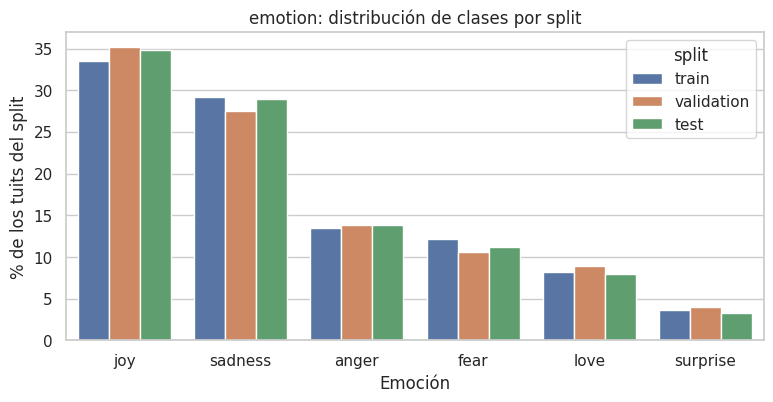

In [8]:
# Distribución de las 6 clases en cada split
conteos = pd.DataFrame({split: df["emocion"].value_counts() for split, df in df_emo.items()})
conteos = conteos.loc[conteos["train"].sort_values(ascending=False).index]
porcentajes = (conteos / conteos.sum() * 100).round(1)
display(conteos.join(porcentajes, rsuffix=" (%)"))
razon = conteos["train"].max() / conteos["train"].min()
print(f"En train, la clase más grande tiene {razon:.1f} veces más tuits que la más pequeña")

fig, ax = plt.subplots(figsize=(9, 4))
largo = porcentajes.reset_index(names="emoción").melt(
    id_vars="emoción", var_name="split", value_name="porcentaje"
)
sns.barplot(data=largo, x="emoción", y="porcentaje", hue="split", ax=ax)
ax.set(
    title="emotion: distribución de clases por split",
    xlabel="Emoción",
    ylabel="% de los tuits del split",
)
guardar(fig, "t1_distribucion_clases")
plt.show()

El dataset está desbalanceado. joy (33.5 %) y sadness (29.2 %) suman casi dos tercios del train, mientras que surprise tiene solo 572 tuits (3.6 %): la clase más grande tiene 9.4 veces más ejemplos que la más pequeña. Los tres splits tienen casi las mismas proporciones (ninguna clase cambia más de 1.7 puntos de un split a otro), así que validación y test se parecen al train.

In [9]:
# Tuits repetidos: dentro del train, con etiquetas distintas y entre splits
textos_train = set(train_emo[TEXT_COL])
etiquetas_por_texto = train_emo.groupby(TEXT_COL)["emocion"].agg(lambda e: sorted(set(e)))
conflictos = etiquetas_por_texto[etiquetas_por_texto.map(len) > 1]

print(f"Tuits repetidos dentro del train: {train_emo[TEXT_COL].duplicated().sum()}")
print(f"De esos, con etiquetas distintas: {len(conflictos)}")
for split in ["validation", "test"]:
    print(f"Tuits de {split} que también están en train: {df_emo[split][TEXT_COL].isin(textos_train).sum()}")

print("Pares de etiquetas en los repetidos:", conflictos.map(" / ".join).value_counts().to_dict())
display(conflictos.head(3).rename("etiquetas").to_frame())

Tuits repetidos dentro del train: 31
De esos, con etiquetas distintas: 30
Tuits de validation que también están en train: 5
Tuits de test que también están en train: 11
Pares de etiquetas en los repetidos: {'joy / love': 15, 'fear / surprise': 6, 'anger / fear': 4, 'anger / sadness': 3, 'joy / surprise': 1, 'fear / sadness': 1}


,etiquetas
text,
i am not amazing or great at photography but i feel passionate about it,"[joy, love]"
i began to feel accepted by gaia on her own terms,"[joy, love]"
i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,"[anger, fear]"


Hay 31 tuits repetidos dentro del train y 30 de ellos tienen etiquetas distintas en cada copia. La mitad de esos casos son joy contra love (15) y les siguen fear contra surprise (6) y anger contra fear (4). Es una señal de que las etiquetas tienen ruido, lo que tiene sentido con una anotación automática por hashtags. Además, 5 tuits de validación y 11 de test también están en el train. Son menos del 1 % de cada split y no los quito, para que mis resultados se puedan comparar con los de otros trabajos que usan este dataset.

media  p50  p95  p99  máx
train      palabras   19.2   17   41   52   66
           tokens     22.3   20   45   57   87
validation palabras   18.9   17   40   52   61
           tokens     21.9   20   44   56   69
test       palabras   19.2   17   41   52   61
           tokens     22.2   20   45   55   66

Tuits con más de 64 tokens (los tres splits): 0.15%
Tuits con más de 128 tokens (los tres splits): 0.00%


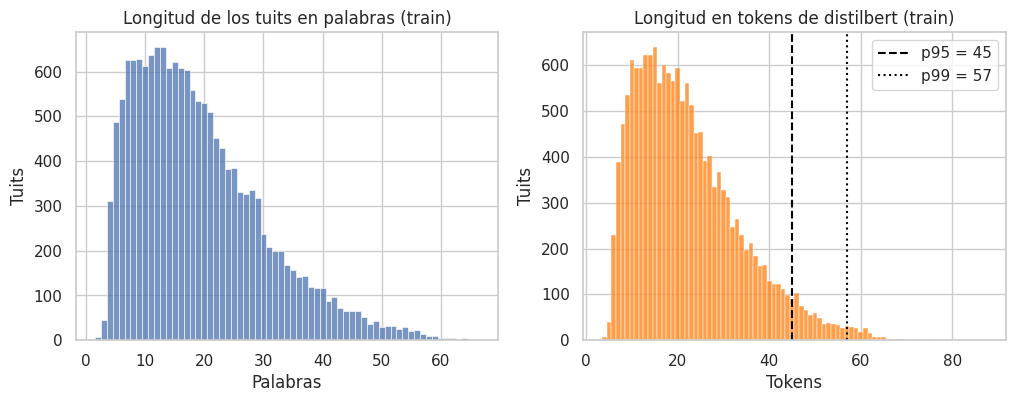

In [10]:
# Longitud de los tuits en palabras y en tokens de distilbert (solo el tokenizer, sin el modelo)
from transformers import AutoTokenizer

tok_emo = AutoTokenizer.from_pretrained(MODEL_ID)
for df in df_emo.values():
    df["palabras"] = df[TEXT_COL].str.split().str.len()
    # Sin truncar y con [CLS] y [SEP], que es lo que ve el modelo
    ids = tok_emo(df[TEXT_COL].tolist(), verbose=False)["input_ids"]
    df["tokens"] = [len(x) for x in ids]

display(tabla_longitudes(df_emo, ["palabras", "tokens"]))
todos = pd.concat(df_emo.values())
for limite in (64, 128):
    print(f"Tuits con más de {limite} tokens (los tres splits): {(todos['tokens'] > limite).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_emo["palabras"], discrete=True, ax=axes[0])
axes[0].set(title="Longitud de los tuits en palabras (train)", xlabel="Palabras", ylabel="Tuits")
sns.histplot(train_emo["tokens"], discrete=True, ax=axes[1], color="tab:orange")
marcar_percentiles(axes[1], train_emo["tokens"])
axes[1].set(title="Longitud en tokens de distilbert (train)", xlabel="Tokens", ylabel="Tuits")
guardar(fig, "t1_longitudes")
plt.show()

Los tuits son cortos: 19 palabras y 22 tokens en promedio. El 95 % tiene 45 tokens o menos, el más largo tiene 87 y solo el 0.15 % pasa de 64. Ninguno llega a 128. Hay un poco más de tokens que de palabras porque se suman [CLS] y [SEP] y porque las palabras poco comunes se parten en subpalabras.

#### Qué implica para el entrenamiento

- max_length: uso `max_length=128`, con el que no se corta ningún tuit (el más largo tiene 87 tokens). Podría bajar a 64 y perder solo el 0.15 %, pero con padding dinámico (`DataCollatorWithPadding`) cada batch se rellena hasta su tuit más largo, así que el límite casi no cambia el costo.
- Métrica: la principal es F1 macro, que promedia el F1 de las seis clases con el mismo peso. Con un desbalance de 9.4 a 1, un modelo que nunca prediga surprise perdería apenas 3.6 puntos de accuracy, mientras que su F1 macro podría bajar hasta 16.7 puntos, porque esa clase pesa un sexto. El paper del dataset también usa F1 por el desbalance. Además reporto accuracy, el F1 de cada clase y la matriz de confusión.
- Desbalance: como los splits tienen las mismas proporciones, no hace falta repartirlos de nuevo. La muestra para la búsqueda de learning rate la saco estratificada por etiqueta, para que surprise no quede con muy pocos ejemplos. Primero entreno sin pesos por clase; si el F1 de surprise o de love queda muy bajo, pruebo pesos inversos a la frecuencia en la función de pérdida.
- Ruido: por los repetidos con etiquetas distintas, no espero llegar al 100 %, y es probable que el modelo confunda joy con love y fear con surprise. Eso lo reviso en la matriz de confusión.
- Modelo: el texto está en minúsculas, así que distilbert uncased no pierde información por no distinguir mayúsculas.

### 1.3 Búsqueda de hiperparámetros

Primero preparo los datos. Tokenizo los tuits con `max_length=128`, que sale del EDA, y el padding lo hace `DataCollatorWithPadding` en cada batch. El modelo es distilbert con una cabeza de clasificación nueva: dos capas lineales sobre el vector del primer token (`[CLS]`) que terminan en las 6 emociones. Esa cabeza empieza con pesos al azar, así que fijo la semilla antes de crear cada modelo para que todas las corridas arranquen igual. Por eso mismo transformers imprime un reporte de capas que faltan en el checkpoint cada vez que creo el modelo; lo filtré en la celda de utilidades porque es lo esperado.

En la prueba rápida, `recortar()` deja 400 tuits de train y 200 de validación y de test. En Colab se usan los splits completos.

In [ ]:
# Tarea 1: configuración del fine-tuning y datos tokenizados
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, set_seed

REENTRENAR = False  # True para repetir la búsqueda, el entrenamiento y el test aunque ya estén guardados
T1_DIR = RESULTADOS_DIR / "tarea1"
T1_DIR.mkdir(parents=True, exist_ok=True)

MAX_LENGTH = 128  # del EDA: el tuit más largo tiene 87 tokens
LEARNING_RATES = [1e-5, 2e-5, 3e-5, 5e-5, 8e-5, 1e-4]  # 8e-5 y 1e-4 por si el mejor queda en el borde de arriba
EPOCAS_BUSQUEDA = 2
EPOCAS_FINAL = 3
N_BUSQUEDA = 160 if MODO_RAPIDO else 4000  # tuits de la muestra estratificada para la búsqueda

tok_t1 = AutoTokenizer.from_pretrained(MODEL_ID)
colador_t1 = DataCollatorWithPadding(tok_t1)  # padding dinámico: cada batch hasta su tuit más largo


def tokenizar_t1(batch):
    return tok_t1(batch[TEXT_COL], truncation=True, max_length=MAX_LENGTH)


ds_t1 = ds_emo.map(tokenizar_t1, batched=True)
train_t1 = recortar(ds_t1["train"], 400)
val_t1 = recortar(ds_t1["validation"], 200)
test_t1 = recortar(ds_t1["test"], 200)
muestra_t1 = train_t1.train_test_split(train_size=N_BUSQUEDA, stratify_by_column=LABEL_COL, seed=SEED)["train"]


def modelo_t1():
    """distilbert con una cabeza nueva de 6 clases. La semilla fija los pesos iniciales de la cabeza."""
    set_seed(SEED)
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        num_labels=len(CLASES_EMO),
        id2label=dict(enumerate(CLASES_EMO)),
        label2id={clase: i for i, clase in enumerate(CLASES_EMO)},
    )


def metricas_clasificacion(y_real, y_pred):
    # zero_division=0: una clase que el modelo nunca predice cuenta con F1 de 0
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "f1_macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
    }


def metricas_t1(pred):
    return metricas_clasificacion(pred.label_ids, pred.predictions.argmax(-1))


print(f"Resultados de la tarea 1 en {ruta(T1_DIR)}")
tamanos = {"train": train_t1, "muestra para la búsqueda": muestra_t1, "validation": val_t1, "test": test_t1}
display(pd.DataFrame({"tuits": {nombre: len(ds) for nombre, ds in tamanos.items()}}).T)

Antes de ajustar distilbert entreno una línea base clásica: TF-IDF de palabras y bigramas con regresión logística, con el mismo train y evaluada en la misma validación. No le busco hiperparámetros porque solo la quiero como punto de comparación. Si el fine-tuning no le gana con claridad, algo está fallando. Tarda unos segundos, así que no la guardo: se vuelve a entrenar cada vez.

In [12]:
# Línea base: TF-IDF de palabras y bigramas + regresión logística, con el mismo train
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

linea_base_t1 = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000),
)
linea_base_t1.fit(list(train_t1[TEXT_COL]), list(train_t1[LABEL_COL]))
base_val_t1 = metricas_clasificacion(list(val_t1[LABEL_COL]), linea_base_t1.predict(list(val_t1[TEXT_COL])))

aviso_prueba_rapida()
print(f"Vocabulario de TF-IDF: {len(linea_base_t1[0].vocabulary_)} términos")
display(pd.DataFrame({"línea base en validación": base_val_t1}).T.round(4))

Vocabulario de TF-IDF: 32995 términos


,accuracy,f1_macro
línea base en validación,0.831,0.7553


La búsqueda es solo sobre el learning rate, como quedó en `docs/seleccion_datasets.md`. Pruebo 1e-5, 2e-5, 3e-5 y 5e-5 (los tres que recomienda el paper de BERT más 1e-5), y además 8e-5 y 1e-4. Esos dos están para comprobar que el mejor valor no queda en el borde de arriba de la grilla: si gana el más alto, no sé si uno mayor sería todavía mejor. Todas las corridas usan batch 16 y 2 épocas, sobre una muestra estratificada de 4000 tuits del train. Con la muestra cada corrida tarda poco, y al estratificarla se mantienen las proporciones de las clases, así que surprise conserva su 3.6 %. Cada corrida se evalúa con la validación completa y escojo el learning rate con mejor F1 macro al final de la segunda época. Todo lo demás es igual en todas las corridas: el modelo de partida, la semilla y los datos.

La tabla se guarda después de cada learning rate. Si Colab se cae a mitad de la búsqueda, o si agrego valores a la lista, al volver a correr la celda solo entrena los que faltan. Después muestro la tabla ordenada y una gráfica del F1 macro contra el learning rate, con la línea base como referencia.

In [13]:
# Búsqueda de learning rate sobre la muestra estratificada, sin checkpoints
archivo_busqueda_t1 = T1_DIR / "busqueda_lr.csv"
filas = pd.read_csv(archivo_busqueda_t1).to_dict("records") if archivo_busqueda_t1.exists() and not REENTRENAR else []
hechos = {fila["learning_rate"] for fila in filas}
if hechos:
    print(f"Cargo de {ruta(archivo_busqueda_t1)} los learning rates ya probados: "
          f"{', '.join(f'{lr:g}' for lr in sorted(hechos))} (REENTRENAR = True para repetirlos)")

for lr in [lr for lr in LEARNING_RATES if lr not in hechos]:
    print(f"--- learning rate {lr:g}")
    trainer = Trainer(
        model=modelo_t1(),
        args=argumentos(CHECKPOINTS_DIR / "t1_busqueda", learning_rate=lr, num_train_epochs=EPOCAS_BUSQUEDA),
        train_dataset=muestra_t1,
        eval_dataset=val_t1,
        processing_class=tok_t1,
        data_collator=colador_t1,
        compute_metrics=metricas_t1,
    )
    historial, velocidad = entrenar(trainer)
    ultima = historial.iloc[-1]  # la última época
    filas.append({
        "learning_rate": lr,
        "f1_macro": ultima["f1_macro"],
        "accuracy": ultima["accuracy"],
        "loss_val": ultima["loss_val"],
        "loss_train": ultima["loss_train"],
        "tuits": len(muestra_t1),
        **velocidad,
    })
    pd.DataFrame(filas).to_csv(archivo_busqueda_t1, index=False)  # por si Colab se cae a mitad
    del trainer
    liberar_memoria()

busqueda_t1 = pd.DataFrame(filas).sort_values("f1_macro", ascending=False, ignore_index=True)
shutil.rmtree(CHECKPOINTS_DIR / "t1_busqueda", ignore_errors=True)  # el Trainer crea la carpeta aunque no guarde
aviso_prueba_rapida()
display(busqueda_t1.round(4).assign(learning_rate=busqueda_t1["learning_rate"].map("{:g}".format)))
print(f"Tiempo total de la búsqueda: {busqueda_t1['segundos_entrenamiento'].sum():.0f} s")

--- learning rate 1e-05
época 1  loss_train 1.3988  loss_val 0.9742  accuracy 0.6630  f1_macro 0.4034
época 2  loss_train 0.8277  loss_val 0.7594  accuracy 0.7500  f1_macro 0.5184
Tiempo: 52.5 s (152.3 muestras/s)
--- learning rate 2e-05
época 1  loss_train 1.1684  loss_val 0.6233  accuracy 0.7945  f1_macro 0.6168
época 2  loss_train 0.4547  loss_val 0.4149  accuracy 0.8695  f1_macro 0.7757
Tiempo: 45.7 s (175.2 muestras/s)
--- learning rate 3e-05
época 1  loss_train 1.0278  loss_val 0.4562  accuracy 0.8670  f1_macro 0.7623
época 2  loss_train 0.2990  loss_val 0.2952  accuracy 0.9085  f1_macro 0.8704
Tiempo: 42.9 s (186.7 muestras/s)
--- learning rate 5e-05
época 1  loss_train 0.8721  loss_val 0.3126  accuracy 0.8930  f1_macro 0.8554
época 2  loss_train 0.2050  loss_val 0.2491  accuracy 0.9215  f1_macro 0.8965
Tiempo: 21.3 s (376.1 muestras/s)


,learning_rate,f1_macro,accuracy,loss_val,loss_train,tuits,segundos_entrenamiento,muestras_por_segundo
0,5e-05,0.8965,0.9215,0.2491,0.2050,4000,21.3,376.1
1,3e-05,0.8704,0.9085,0.2952,0.2990,4000,42.9,186.7
2,2e-05,0.7757,0.8695,0.4149,0.4547,4000,45.7,175.2
3,1e-05,0.5184,0.7500,0.7594,0.8277,4000,52.5,152.3


Tiempo total de la búsqueda: 162 s


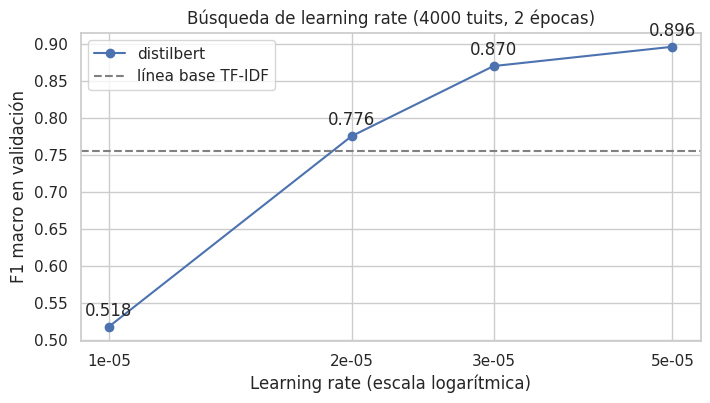

In [14]:
# F1 macro en validación contra learning rate
orden = busqueda_t1.sort_values("learning_rate")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(orden["learning_rate"], orden["f1_macro"], marker="o", label="distilbert")
for lr, f1 in zip(orden["learning_rate"], orden["f1_macro"]):
    ax.annotate(f"{f1:.3f}", (lr, f1), textcoords="offset points", xytext=(0, 8), ha="center")
ax.axhline(base_val_t1["f1_macro"], color="gray", linestyle="--", label="línea base TF-IDF")
ax.set_xscale("log")
ax.set_xticks(orden["learning_rate"], [f"{lr:g}" for lr in orden["learning_rate"]])
ax.set_xticks([], minor=True)
ax.set(
    title=titulo(f"Búsqueda de learning rate ({len(muestra_t1)} tuits, {EPOCAS_BUSQUEDA} épocas)"),
    xlabel="Learning rate (escala logarítmica)",
    ylabel="F1 macro en validación",
)
ax.legend()
guardar(fig, "t1_busqueda_lr", carpeta=FIG_ENTRENAMIENTO_DIR)
plt.show()

### 1.4 Entrenamiento con la data completa

El learning rate sale de la primera fila de la tabla de 1.3, que está ordenada por F1 macro. No lo escribo a mano, para que si repito o amplío la búsqueda el entrenamiento use el valor nuevo. Si ya hay un modelo guardado pero se entrenó con otro learning rate o con otro número de épocas, la celda lo entrena de nuevo sin que tenga que poner `REENTRENAR = True`. Entreno con los 16000 tuits del train durante 3 épocas y evalúo en validación al final de cada una. Al terminar, el Trainer carga la época con mejor F1 macro (`load_best_model_at_end`), que no tiene por qué ser la última. Ese modelo queda guardado con su tokenizer en `OUTPUT_DIR/tarea1/modelo`, junto con el historial por época y el tiempo de entrenamiento.

En las gráficas reviso si la loss de validación empieza a subir mientras la de train sigue bajando, que sería señal de sobreajuste, y en qué época deja de mejorar el F1 macro.

In [ ]:
# Entrenamiento con todo el train y el mejor learning rate de 1.3
MEJOR_LR_T1 = float(busqueda_t1.loc[0, "learning_rate"])  # la tabla está ordenada por F1 macro
dir_modelo_t1 = T1_DIR / "modelo"
archivo_historial_t1 = T1_DIR / "historial_entrenamiento.csv"
archivo_entrenamiento_t1 = T1_DIR / "entrenamiento.json"  # se escribe al final: si existe, todo terminó

# Reuso el modelo guardado solo si se entrenó con el learning rate y las épocas de ahora
info_t1 = cargar_si_vigente(archivo_entrenamiento_t1, {"learning_rate": MEJOR_LR_T1, "epocas": EPOCAS_FINAL}, REENTRENAR)
if info_t1 is not None:
    historial_t1 = pd.read_csv(archivo_historial_t1)
    print(f"Cargo el entrenamiento guardado en {ruta(T1_DIR)} (REENTRENAR = True para repetirlo).")
else:
    ckpt_t1 = CHECKPOINTS_DIR / "tarea1"
    trainer = Trainer(
        model=modelo_t1(),
        args=argumentos(
            ckpt_t1,
            learning_rate=MEJOR_LR_T1,
            num_train_epochs=EPOCAS_FINAL,
            save_strategy="best",  # checkpoint solo cuando mejora el F1 macro de validación
            save_only_model=True,  # solo los pesos, sin el estado del optimizador
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="f1_macro",
        ),
        train_dataset=train_t1,
        eval_dataset=val_t1,
        processing_class=tok_t1,
        data_collator=colador_t1,
        compute_metrics=metricas_t1,
    )
    print(f"learning rate {MEJOR_LR_T1:g}, {len(train_t1)} tuits, {EPOCAS_FINAL} épocas")
    historial_t1, velocidad = entrenar(trainer)
    trainer.save_model(dir_modelo_t1)  # el de la mejor época, con su tokenizer
    historial_t1.to_csv(archivo_historial_t1, index=False)
    mejor = historial_t1.loc[historial_t1["f1_macro"].idxmax()]
    info_t1 = {
        "learning_rate": MEJOR_LR_T1,
        "epocas": EPOCAS_FINAL,
        "mejor_epoca": int(mejor["época"]),
        "f1_macro_val": float(mejor["f1_macro"]),
        "tuits_train": len(train_t1),
        **velocidad,
    }
    guardar_json(info_t1, archivo_entrenamiento_t1)
    shutil.rmtree(ckpt_t1, ignore_errors=True)  # el modelo final ya quedó guardado
    del trainer
    liberar_memoria()

aviso_prueba_rapida()
display(historial_t1.round(4))
print(f"Mejor época: {info_t1['mejor_epoca']} (F1 macro {info_t1['f1_macro_val']:.4f}), guardada en {ruta(dir_modelo_t1)}")
print(f"Entrenamiento: {info_t1['segundos_entrenamiento']} s, {info_t1['muestras_por_segundo']} muestras/s")

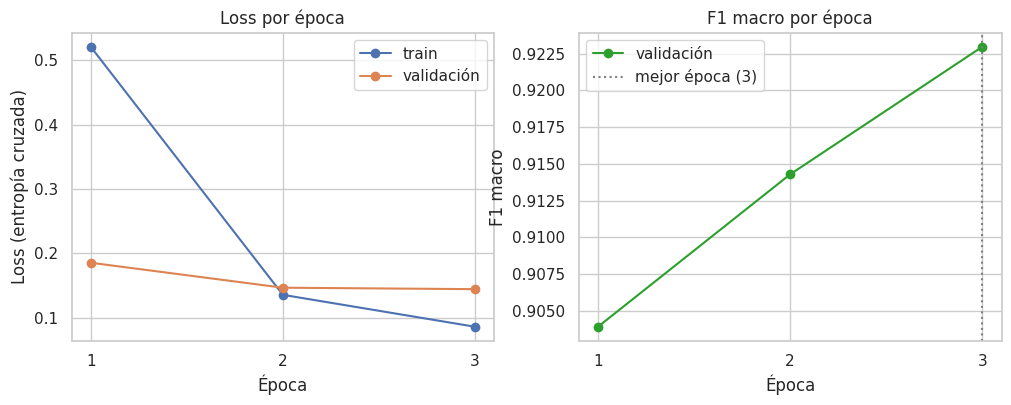

In [16]:
# Loss de train y validación, y F1 macro de validación por época
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas = historial_t1["época"]
axes[0].plot(epocas, historial_t1["loss_train"], marker="o", label="train")
axes[0].plot(epocas, historial_t1["loss_val"], marker="o", label="validación")
axes[0].set(title=titulo("Loss por época"), xlabel="Época", ylabel="Loss (entropía cruzada)", xticks=epocas)
axes[0].legend()
axes[1].plot(epocas, historial_t1["f1_macro"], marker="o", color="tab:green", label="validación")
axes[1].axvline(info_t1["mejor_epoca"], color="gray", linestyle=":", label=f"mejor época ({info_t1['mejor_epoca']})")
axes[1].set(title=titulo("F1 macro por época"), xlabel="Época", ylabel="F1 macro", xticks=epocas)
axes[1].legend()
guardar(fig, "t1_entrenamiento", carpeta=FIG_ENTRENAMIENTO_DIR)
plt.show()

### 1.5 Evaluación del mejor modelo

Cargo el modelo desde la carpeta donde quedó guardado, para evaluar exactamente lo que queda en Drive. El test lo evalúo una sola vez: las predicciones se guardan junto con el learning rate y las épocas del modelo que las produjo, y si vuelvo a correr la celda las carga en vez de predecir otra vez. Solo predice de nuevo si el modelo de 1.4 cambió, por ejemplo porque la búsqueda dio otro learning rate. Con el mismo modelo vuelvo a predecir la validación. Su F1 macro tiene que coincidir con el de la mejor época de 1.4, y eso confirma que guardé la época correcta.

In [ ]:
# Predicciones del modelo guardado en validación y test (el test se evalúa una sola vez)
archivo_pred_t1 = T1_DIR / "predicciones.csv"
archivo_metricas_t1 = T1_DIR / "metricas_val_test.json"
# Con qué modelo salen las predicciones. Si el de 1.4 cambia, las guardadas ya no le corresponden.
config_modelo_t1 = {k: info_t1[k] for k in ("learning_rate", "epocas", "mejor_epoca")}

guardadas_t1 = cargar_si_vigente(archivo_metricas_t1, config_modelo_t1, REENTRENAR)
if guardadas_t1 is not None:
    pred_t1 = pd.read_csv(archivo_pred_t1)
    print(f"Cargo las predicciones guardadas en {ruta(archivo_pred_t1)}: el test no se vuelve a evaluar.")
else:
    modelo_final_t1 = AutoModelForSequenceClassification.from_pretrained(dir_modelo_t1)
    tok_final_t1 = AutoTokenizer.from_pretrained(dir_modelo_t1)
    evaluador = Trainer(
        model=modelo_final_t1,
        args=argumentos(CHECKPOINTS_DIR / "t1_evaluacion", eval_strategy="no"),
        processing_class=tok_final_t1,
        data_collator=DataCollatorWithPadding(tok_final_t1),
    )
    partes = []
    for split, ds in [("validation", val_t1), ("test", test_t1)]:
        logits = evaluador.predict(ds).predictions
        probs = np.exp(logits - logits.max(axis=1, keepdims=True))
        probs /= probs.sum(axis=1, keepdims=True)  # softmax
        partes.append(pd.DataFrame({
            "split": split,
            "texto": list(ds[TEXT_COL]),
            "real": list(ds[LABEL_COL]),
            "pred": probs.argmax(axis=1),
            "confianza": probs.max(axis=1),
        }))
    pred_t1 = pd.concat(partes, ignore_index=True)
    guardadas_t1 = config_modelo_t1 | {
        split: metricas_clasificacion(grupo["real"], grupo["pred"]) for split, grupo in pred_t1.groupby("split")
    }
    pred_t1.to_csv(archivo_pred_t1, index=False)
    guardar_json(guardadas_t1, archivo_metricas_t1)
    print(f"Predicciones guardadas en {ruta(archivo_pred_t1)} y métricas en {ruta(archivo_metricas_t1)}")
    del evaluador, modelo_final_t1
    shutil.rmtree(CHECKPOINTS_DIR / "t1_evaluacion", ignore_errors=True)
    liberar_memoria()

metricas_finales_t1 = {split: guardadas_t1[split] for split in ("validation", "test")}
pred_test_t1 = pred_t1[pred_t1["split"] == "test"]
print(f"Modelo: lr {config_modelo_t1['learning_rate']:g}, mejor época {config_modelo_t1['mejor_epoca']} de {config_modelo_t1['epocas']}")

Reporto accuracy y F1 macro en validación y en test, el reporte por clase del test (precisión, recall y F1) y la matriz de confusión normalizada por fila. En esa matriz cada fila es una clase real y suma 1, así que la diagonal es el recall de cada clase y se pueden comparar clases de tamaños muy distintos, como joy y surprise.

In [18]:
# Métricas en validación y test, y reporte por clase del test
from sklearn.metrics import classification_report, confusion_matrix

aviso_prueba_rapida()
display(pd.DataFrame(metricas_finales_t1).T.loc[["validation", "test"]].round(4))
print(f"F1 macro de la mejor época en 1.4: {info_t1['f1_macro_val']:.4f} (tiene que coincidir con validation)")

reporte_t1 = classification_report(
    pred_test_t1["real"], pred_test_t1["pred"],
    labels=range(len(CLASES_EMO)), target_names=CLASES_EMO, output_dict=True, zero_division=0,
)
reporte_t1 = pd.DataFrame(reporte_t1).T.drop(index="accuracy")
reporte_t1["support"] = reporte_t1["support"].astype(int)
display(reporte_t1.round(3))

,accuracy,f1_macro
validation,0.9455,0.9230
test,0.9295,0.8874


F1 macro de la mejor época en 1.4: 0.9230 (tiene que coincidir con validation)


,precision,recall,f1-score,support
sadness,0.967,0.969,0.968,581
joy,0.942,0.958,0.950,695
love,0.891,0.774,0.828,159
anger,0.916,0.913,0.914,275
fear,0.873,0.924,0.898,224
surprise,0.790,0.742,0.766,66
macro avg,0.897,0.880,0.887,2000
weighted avg,0.929,0.930,0.929,2000


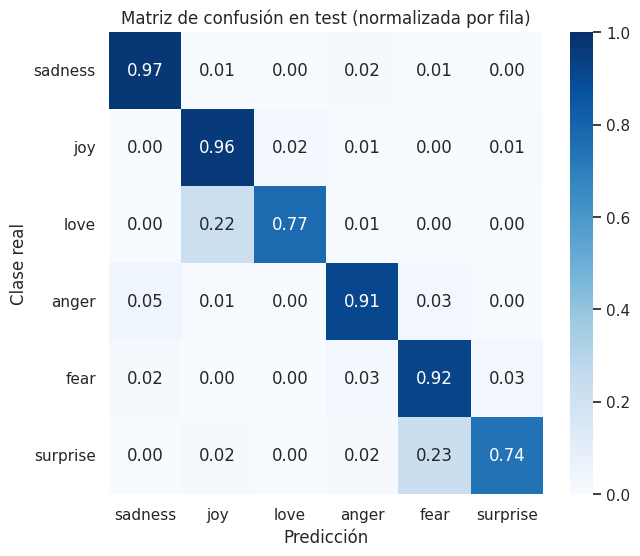

In [19]:
# Matriz de confusión del test, normalizada por fila (cada fila es una clase real)
cm_t1 = confusion_matrix(pred_test_t1["real"], pred_test_t1["pred"], labels=range(len(CLASES_EMO)), normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_t1, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CLASES_EMO, yticklabels=CLASES_EMO, ax=ax)
ax.set(title=titulo("Matriz de confusión en test (normalizada por fila)"), xlabel="Predicción", ylabel="Clase real")
ax.tick_params(axis="y", rotation=0)
guardar(fig, "t1_matriz_confusion", carpeta=FIG_ENTRENAMIENTO_DIR)
plt.show()

Después comparo dos cosas. La primera es validación contra test: escogí el learning rate y la época mirando la validación, así que si el test sale bastante más bajo, esas decisiones se ajustaron demasiado a la validación. La segunda es el fine-tuning contra la línea base de 1.3, ahora también en test y por clase.

In [20]:
# Línea base contra distilbert, en validación y en test
y_test_t1 = list(test_t1[LABEL_COL])
pred_base_test_t1 = linea_base_t1.predict(list(test_t1[TEXT_COL]))
base_test_t1 = metricas_clasificacion(y_test_t1, pred_base_test_t1)

aviso_prueba_rapida()
comparacion_t1 = pd.DataFrame({
    "línea base (TF-IDF + regresión logística)": {
        "accuracy val": base_val_t1["accuracy"], "F1 macro val": base_val_t1["f1_macro"],
        "accuracy test": base_test_t1["accuracy"], "F1 macro test": base_test_t1["f1_macro"],
    },
    "distilbert ajustado": {
        "accuracy val": metricas_finales_t1["validation"]["accuracy"],
        "F1 macro val": metricas_finales_t1["validation"]["f1_macro"],
        "accuracy test": metricas_finales_t1["test"]["accuracy"],
        "F1 macro test": metricas_finales_t1["test"]["f1_macro"],
    },
}).T
display(comparacion_t1.round(4))

# F1 de cada clase en test, para ver en qué clases cambia más
f1_clases_t1 = pd.DataFrame({
    "línea base": f1_score(y_test_t1, pred_base_test_t1, labels=range(len(CLASES_EMO)), average=None, zero_division=0),
    "distilbert": f1_score(pred_test_t1["real"], pred_test_t1["pred"], labels=range(len(CLASES_EMO)), average=None, zero_division=0),
}, index=CLASES_EMO)
f1_clases_t1["diferencia"] = f1_clases_t1["distilbert"] - f1_clases_t1["línea base"]
display(f1_clases_t1.round(3))

,accuracy val,F1 macro val,accuracy test,F1 macro test
línea base (TF-IDF + regresión logística),0.8310,0.7553,0.8305,0.7255
distilbert ajustado,0.9455,0.9230,0.9295,0.8874


,línea base,distilbert,diferencia
sadness,0.887,0.968,0.081
joy,0.863,0.950,0.087
love,0.624,0.828,0.204
anger,0.806,0.914,0.108
fear,0.787,0.898,0.111
surprise,0.386,0.766,0.380


En el EDA vi de dónde podían salir errores. Entre los 30 tuits repetidos del train con etiquetas distintas, las parejas más comunes eran joy/love (15) y fear/surprise (6), y 11 tuits del test también aparecen en el train. Primero cuento qué pares de clases confunde más el modelo. Después muestro los errores de joy contra love y de fear contra surprise en los que el modelo estaba más seguro, y al final reviso qué predice para los tuits del test que ya estaban en el train.

In [21]:
# Errores del test: pares más confundidos y ejemplos de joy/love y fear/surprise
errores_t1 = pred_test_t1[pred_test_t1["real"] != pred_test_t1["pred"]].copy()
errores_t1["real"] = errores_t1["real"].map(dict(enumerate(CLASES_EMO)))
errores_t1["pred"] = errores_t1["pred"].map(dict(enumerate(CLASES_EMO)))

aviso_prueba_rapida()
print(f"Errores en test: {len(errores_t1)} de {len(pred_test_t1)}")
display(errores_t1.value_counts(["real", "pred"]).head(8).rename("errores").reset_index())

pares_eda = [("joy", "love"), ("love", "joy"), ("fear", "surprise"), ("surprise", "fear")]
ejemplos = pd.concat([
    errores_t1[(errores_t1["real"] == real) & (errores_t1["pred"] == pred)].nlargest(2, "confianza")
    for real, pred in pares_eda
])
print("Errores con más confianza en los pares que esperaba por el EDA:")
display(ejemplos[["texto", "real", "pred", "confianza"]].round(3))

Errores en test: 141 de 2000


,real,pred,errores
0,love,joy,35
1,joy,love,15
2,surprise,fear,15
3,anger,sadness,13
4,sadness,anger,10
5,anger,fear,9
6,fear,surprise,7
7,fear,anger,6


Errores con más confianza en los pares que esperaba por el EDA:


,texto,real,pred,confianza
3206,ive come to feel about a supporting character in one of my all time favorite films giant,joy,love,0.997
2845,i did feel rather like a celebrity and widget stood and let herself be admired while she drank orange squash from my cup,joy,love,0.983
3377,i walked to school he felt the bounce in his step the overjoyed feelings of youth and the thrill of excitement of coming to school and meeting his beloved friends,love,joy,0.995
2326,i just can t feel accepted,love,joy,0.994
3736,i was stressed about my job search and apartment hunting and i was just feeling overwhelmed with everything that was going on,fear,surprise,0.722
3162,i would always have this song stuck in my head after a bombing or incident and then i would feel a bit weird about it because if you dont really pay attention to the lyrics it sounds like such a happy song not the type youre supposed to hum on difficult days,fear,surprise,0.638
3314,ive blogged and i feel strange about it,surprise,fear,0.831
2996,i replied feeling strange at giving the orders,surprise,fear,0.756


In [22]:
# Tuits del test que también están en el train, con las etiquetas que tienen allá
train_df_t1 = ds_emo["train"].to_pandas()
etiquetas_en_train = train_df_t1.groupby(TEXT_COL)[LABEL_COL].agg(
    lambda s: ", ".join(sorted({CLASES_EMO[i] for i in s}))
)
repetidos_t1 = pred_test_t1[pred_test_t1["texto"].isin(etiquetas_en_train.index)].copy()
repetidos_t1["en train"] = repetidos_t1["texto"].map(etiquetas_en_train)
repetidos_t1["real"] = repetidos_t1["real"].map(dict(enumerate(CLASES_EMO)))
repetidos_t1["pred"] = repetidos_t1["pred"].map(dict(enumerate(CLASES_EMO)))

aviso_prueba_rapida()
print(f"{len(repetidos_t1)} tuits del test también están en el train; "
      f"el modelo acierta {(repetidos_t1['real'] == repetidos_t1['pred']).sum()}")
display(repetidos_t1[["texto", "real", "en train", "pred", "confianza"]].round(3))

11 tuits del test también están en el train; el modelo acierta 2


,texto,real,en train,pred,confianza
2262,i realized what i am passionate about helping women feel accepted and appreciated,joy,love,joy,0.676
2265,i feel so blessed and honored that we get to be its parents,love,joy,joy,0.699
2353,i could feel his breath on me and smell the sweet scent of him,joy,love,love,0.932
2415,i loved the feeling i got during an amazing slalom run whether it was in training or in a race,joy,surprise,surprise,0.967
2502,i am feeling stressed and more than a bit anxious,anger,sadness,sadness,0.583
2586,i found myself feeling inhibited and shushing her quite a lot,sadness,fear,fear,0.764
2917,i feel the need to pimp this since raini my beloved rocky casting director loves it so much,joy,love,love,0.673
2959,i feel cared for and accepted,love,joy,joy,0.608
3026,i have not conducted a survey but it is quite likely that many of them feel as assaulted by onel s demons and other creators as i would have felt had the walls been covered only with eminent figures patriotic heroes and epic deeds,sadness,fear,fear,0.969
3275,i feel so weird and scattered with all wonders about a million different things,surprise,fear,fear,0.537


Para terminar, una demo con `pipeline` sobre frases que escribí yo al estilo del dataset: en inglés, en minúsculas, sin puntuación y todas con "i feel". La columna "esperada" es la emoción que yo le pondría a cada frase; no viene del dataset.

In [23]:
# Demo con pipeline sobre frases nuevas al estilo del dataset
from transformers import pipeline

clasificador_t1 = pipeline("text-classification", model=str(dir_modelo_t1), device=DEVICE)
frases_t1 = {
    "i feel so grateful for the friends who helped me move this weekend": "joy",
    "i feel really nervous about the job interview tomorrow morning": "fear",
    "i feel so lonely since my sister moved to another city": "sadness",
    "i feel furious that nobody told me the meeting was cancelled": "anger",
    "i feel so loved when my grandmother cooks my favorite dinner": "love",
    "i feel amazed that the kids learned to swim in just one week": "surprise",
}
salidas = clasificador_t1(list(frases_t1), top_k=2)

aviso_prueba_rapida()
display(pd.DataFrame([
    {
        "frase": frase,
        "esperada": esperada,
        "predicción": top[0]["label"],
        "confianza": round(top[0]["score"], 3),
        "segunda opción": f"{top[1]['label']} ({top[1]['score']:.3f})",
    }
    for (frase, esperada), top in zip(frases_t1.items(), salidas)
]))

,frase,esperada,predicción,confianza,segunda opción
0,i feel so grateful for the friends who helped me move this weekend,joy,joy,0.996,love (0.002)
1,i feel really nervous about the job interview tomorrow morning,fear,fear,0.999,surprise (0.000)
2,i feel so lonely since my sister moved to another city,sadness,sadness,1.000,anger (0.000)
3,i feel furious that nobody told me the meeting was cancelled,anger,anger,0.999,fear (0.000)
4,i feel so loved when my grandmother cooks my favorite dinner,love,love,0.998,joy (0.001)
5,i feel amazed that the kids learned to swim in just one week,surprise,surprise,0.997,fear (0.001)


La última celda sube el modelo a mi cuenta de Hugging Face. Está apagada (`SUBIR_AL_HUB = False`), no sube el modelo de la prueba rápida y necesita un token con permiso de escritura. La dejo lista para decidir después si lo publico.

In [24]:
# Subir el modelo a mi cuenta de Hugging Face (apagado por defecto)
SUBIR_AL_HUB = False
NOMBRE_REPO_T1 = "distilbert-base-uncased-emotion-proyecto2"
REPO_PRIVADO = True  # lo cambio a False si quiero que sea público

if not SUBIR_AL_HUB:
    print("SUBIR_AL_HUB = False: no se sube nada.")
elif MODO_RAPIDO:
    print("Este es el modelo de la prueba rápida: no lo subo.")
else:
    repo_t1 = f"{whoami()['name']}/{NOMBRE_REPO_T1}"
    modelo_hub = AutoModelForSequenceClassification.from_pretrained(dir_modelo_t1)
    tok_hub = AutoTokenizer.from_pretrained(dir_modelo_t1)
    mensaje = f"distilbert ajustado en dair-ai/emotion (lr {info_t1['learning_rate']:g}, época {info_t1['mejor_epoca']})"
    modelo_hub.push_to_hub(repo_t1, private=REPO_PRIVADO, commit_message=mensaje)
    tok_hub.push_to_hub(repo_t1, private=REPO_PRIVADO, commit_message="tokenizer")
    print(f"Subido a https://huggingface.co/{repo_t1}")

SUBIR_AL_HUB = False: no se sube nada.


## Tarea 2: Etiquetado de secuencias

Reconocer entidades nombradas en noticias en español con BETO (`bert-base-spanish-wwm-cased`).

In [ ]:
# Tarea 2: constantes
DATASET_ID = "BramVanroy/conll2002"
DATASET_CONFIG = "es"
MODEL_ID = "dccuchile/bert-base-spanish-wwm-cased"

### 2.1 Descripción del dataset

El problema es reconocer entidades nombradas (NER) en noticias en español: encontrar en cada frase los nombres de personas, organizaciones, lugares y otras entidades. Sirve para sacar información estructurada de texto libre, por ejemplo para indexar noticias según las personas o empresas que mencionan.

- Entrada: una frase que ya viene separada en palabras (columna `tokens`).
- Salida: una etiqueta por palabra (columna `ner_tags`) en formato BIO, con cuatro tipos de entidad: PER (personas), ORG (organizaciones), LOC (lugares) y MISC (otras entidades). B- marca la primera palabra de una entidad, I- las siguientes y O las palabras que no son entidad. En total son 9 etiquetas.
- Tipo de problema: etiquetado de secuencias, o clasificación de tokens. Se clasifica cada palabra por separado, así que la salida tiene la misma longitud que la entrada.
- Tamaño: 8324 frases de train, 1916 de validación y 1518 de test. Son los archivos `train`, `testa` y `testb` del shared task original.
- Origen y anotación: es la parte en español del shared task CoNLL-2002. Son noticias de la agencia EFE de mayo de 2000. La anotación la hicieron el centro TALP de la Universidad Politécnica de Cataluña (UPC) y el CLiC de la Universidad de Barcelona (UB), con financiación del proyecto europeo NAMIC.
- `BramVanroy/conll2002` es una copia exacta de `eriktks/conll2002` en formato parquet. La original ya no carga con datasets 5 porque depende de un script.
- Licencia: según la card, no se sabe cuál es la licencia de los datos, en especial la del texto de las noticias ("unknown"). Lo uso solo con fines académicos.
- Cita: Tjong Kim Sang, E. F. (2002). Introduction to the CoNLL-2002 Shared Task: Language-Independent Named Entity Recognition. En *COLING-02: The 6th Conference on Natural Language Learning 2002 (CoNLL-2002)*. https://www.aclweb.org/anthology/W02-2024

El modelo es `dccuchile/bert-base-spanish-wwm-cased` (BETO), un BERT base de 110 M de parámetros preentrenado con texto en español. Uso la versión cased porque las mayúsculas ayudan a reconocer nombres propios. Su card reporta 88.43 de F1 en este dataset, medido sobre validación (el enlace del resultado apunta a un archivo `dev_results`). Con ese número voy a comparar mi resultado en validación.

In [ ]:
# Carga del dataset y tamaño de cada split
from datasets import load_dataset

ds_ner = load_dataset(DATASET_ID, DATASET_CONFIG)
ETIQUETAS_NER = ds_ner["train"].features["ner_tags"].feature.names
ETIQUETAS_POS = ds_ner["train"].features["pos_tags"].feature.names

display(pd.DataFrame({"frases": {split: ds_ner[split].num_rows for split in ds_ner}}).T)
print("Columnas:", ds_ner["train"].column_names)
print("Etiquetas NER:", dict(enumerate(ETIQUETAS_NER)))

,train,validation,test
frases,8324,1916,1518


Columnas: ['id', 'tokens', 'pos_tags', 'ner_tags']
Etiquetas NER: {0: 'O', 1: 'B-PER', 2: 'I-PER', 3: 'B-ORG', 4: 'I-ORG', 5: 'B-LOC', 6: 'I-LOC', 7: 'B-MISC', 8: 'I-MISC'}


### 2.2 Análisis exploratorio (EDA)

In [ ]:
# Funciones para pasar de etiquetas BIO a entidades
def entidades_bio(etiquetas):
    """Lista de (tipo, inicio, fin). Un I- sin B- antes también abre una entidad."""
    spans, tipo, inicio = [], None, None
    for i, et in enumerate([*etiquetas, "O"]):
        nueva = et.startswith("B-") or (et.startswith("I-") and et[2:] != tipo)
        if tipo is not None and (et == "O" or nueva):
            spans.append((tipo, inicio, i))
            tipo = None
        if nueva:
            tipo, inicio = et[2:], i
    return spans


def marcar_entidades(tokens, etiquetas):
    """Frase con las entidades entre corchetes, por ejemplo [PER Juan Pérez]."""
    spans = {inicio: (tipo, fin) for tipo, inicio, fin in entidades_bio(etiquetas)}
    partes, i = [], 0
    while i < len(tokens):
        if i in spans:
            tipo, fin = spans[i]
            partes.append(f"[{tipo} {' '.join(tokens[i:fin])}]")
            i = fin
        else:
            partes.append(tokens[i])
            i += 1
    return " ".join(partes)


df_ner = {}
for split in ds_ner:
    df = ds_ner[split].to_pandas()
    df["tokens"] = df["tokens"].map(list)
    df["etiquetas"] = df["ner_tags"].map(lambda ids: [ETIQUETAS_NER[i] for i in ids])
    df["pos"] = df["pos_tags"].map(lambda ids: [ETIQUETAS_POS[i] for i in ids])
    df_ner[split] = df
train_ner = df_ner["train"]

# Muchas "frases" son el encabezado de la noticia (ciudad, fecha y EFE)
encabezado = train_ner["tokens"].map(lambda t: "EFE" in t or "EFECOM" in t)
print(f"Frases de train que mencionan EFE o EFECOM (encabezados de noticia): {encabezado.mean():.1%}\n")

# Dos frases del train que no son encabezado, de 10 a 25 palabras y con al menos tres tipos de entidad
tipos = train_ner["etiquetas"].map(lambda ets: {t for t, _, _ in entidades_bio(ets)})
candidatas = train_ner[(tipos.map(len) >= 3) & train_ner["tokens"].map(len).between(10, 25) & ~encabezado]
muestra = candidatas.sample(2, random_state=SEED)
for _, fila in muestra.iterrows():
    print(marcar_entidades(fila["tokens"], fila["etiquetas"]), end="\n\n")

Frases de train que mencionan EFE o EFECOM (encabezados de noticia): 10.9%

[ORG Ecuality] está en [LOC Argentina] , [LOC Chile] , [LOC México] y [LOC Venezuela] con el nombre [MISC Alcosto] y en [LOC Brasil] y [LOC Portugal] con el dominio [MISC Superoferta.com] .

Pero la meta ulterior de [LOC Chade] para [PER Camacho] , hijo , es enfrentarlo al príncipe [PER Naseem Hamed] , quien reina en la [ORG OMB] .



In [ ]:
# La primera frase palabra por palabra: una etiqueta NER por palabra.
# La fila "pos" es la columna pos_tags, que viene en el dataset pero no uso.
fila = muestra.iloc[0]
display(pd.DataFrame({"palabra": fila["tokens"], "ner": fila["etiquetas"], "pos": fila["pos"]}).T)
print(f"pos_tags tiene {len(ETIQUETAS_POS)} etiquetas gramaticales, por ejemplo {ETIQUETAS_POS[:8]}")

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
palabra,Ecuality,está,en,Argentina,",",Chile,",",México,y,Venezuela,con,el,nombre,Alcosto,y,en,Brasil,y,Portugal,con,el,dominio,Superoferta.com,.
ner,B-ORG,O,O,B-LOC,O,B-LOC,O,B-LOC,O,B-LOC,O,O,O,B-MISC,O,O,B-LOC,O,B-LOC,O,O,O,B-MISC,O
pos,NP,VMI,SP,NC,Fc,NC,Fc,AQ,CC,NC,SP,DA,NC,AQ,CC,SP,NC,CC,NC,SP,DA,NC,AQ,Fp


pos_tags tiene 60 etiquetas gramaticales, por ejemplo ['AO', 'AQ', 'CC', 'CS', 'DA', 'DE', 'DD', 'DI']


El 10.9 % de las frases de train son encabezados de noticia, como "La Coruña , 23 may ( EFECOM ) ." (el ejemplo que da la card), por eso escogí los ejemplos entre las que no lo son. Con los corchetes se ve que una entidad puede tener varias palabras, como [PER Naseem Hamed], y que MISC junta cosas variadas, como el nombre comercial Alcosto o el dominio Superoferta.com. En la tabla, la fila ner es lo que el modelo tiene que predecir: una etiqueta por palabra. La fila pos sale de la columna `pos_tags`, con 60 etiquetas gramaticales, que la card menciona como otra tarea posible con este dataset. En este proyecto solo uso `ner_tags`.

,train,validation,test,train (%),validation (%),test (%)
O,231920,45356,45355,87.61,85.70,88.01
B-PER,4321,1222,735,1.63,2.31,1.43
I-PER,3903,859,634,1.47,1.62,1.23
B-ORG,7390,1700,1400,2.79,3.21,2.72
I-ORG,4992,1366,1104,1.89,2.58,2.14
B-LOC,4913,984,1084,1.86,1.86,2.10
I-LOC,1891,337,325,0.71,0.64,0.63
B-MISC,2173,445,339,0.82,0.84,0.66
I-MISC,3212,654,557,1.21,1.24,1.08


,train,validation,test,train (%),validation (%),test (%)
ORG,7390,1700,1400,39.3,39.1,39.3
LOC,4914,985,1084,26.1,22.6,30.5
PER,4321,1222,735,23.0,28.1,20.7
MISC,2173,445,340,11.6,10.2,9.6


train      tokens O: 87.6 % | frases sin entidades: 25.5% | entidades por frase: 2.26 | I- sin B-: 1 | frases vacías: 1
validation tokens O: 85.7 % | frases sin entidades: 26.5% | entidades por frase: 2.27 | I- sin B-: 1 | frases vacías: 1
test       tokens O: 88.0 % | frases sin entidades: 21.7% | entidades por frase: 2.34 | I- sin B-: 1 | frases vacías: 1


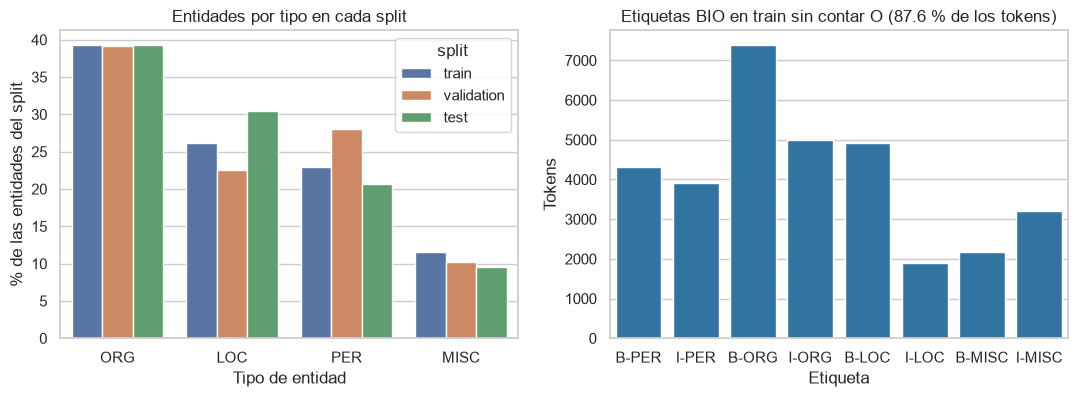

In [ ]:
# Distribución de etiquetas BIO (con O) y de entidades por tipo en cada split
conteo_et = pd.DataFrame(
    {split: Counter(et for ets in df["etiquetas"] for et in ets) for split, df in df_ner.items()}
).reindex(ETIQUETAS_NER).fillna(0).astype(int)
pct_et = (conteo_et / conteo_et.sum() * 100).round(2)
display(conteo_et.join(pct_et, rsuffix=" (%)"))

conteo_ent = pd.DataFrame(
    {split: Counter(t for ets in df["etiquetas"] for t, _, _ in entidades_bio(ets)) for split, df in df_ner.items()}
)
conteo_ent = conteo_ent.loc[conteo_ent["train"].sort_values(ascending=False).index]
pct_ent = (conteo_ent / conteo_ent.sum() * 100).round(1)
display(conteo_ent.join(pct_ent, rsuffix=" (%)"))


def i_sin_b(ets):
    """Cuántas etiquetas I- no vienen después de una etiqueta del mismo tipo."""
    return sum(et.startswith("I-") and (i == 0 or ets[i - 1][2:] != et[2:]) for i, et in enumerate(ets))


for split, df in df_ner.items():
    n_ent = df["etiquetas"].map(lambda ets: len(entidades_bio(ets)))
    print(
        f"{split:<10} tokens O: {pct_et.loc['O', split]:.1f} % | frases sin entidades: {(n_ent == 0).mean():.1%}"
        f" | entidades por frase: {n_ent.mean():.2f} | I- sin B-: {df['etiquetas'].map(i_sin_b).sum()}"
        f" | frases vacías: {(df['tokens'].map(len) == 0).sum()}"
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
largo = pct_ent.reset_index(names="tipo").melt(id_vars="tipo", var_name="split", value_name="porcentaje")
sns.barplot(data=largo, x="tipo", y="porcentaje", hue="split", ax=axes[0])
axes[0].set(title="Entidades por tipo en cada split", xlabel="Tipo de entidad", ylabel="% de las entidades del split")
sin_o = conteo_et["train"].drop(index="O")
sns.barplot(x=sin_o.index, y=sin_o.values, ax=axes[1], color="tab:blue")
axes[1].set(
    title=f"Etiquetas BIO en train sin contar O ({pct_et.loc['O', 'train']:.1f} % de los tokens)",
    xlabel="Etiqueta",
    ylabel="Tokens",
)
guardar(fig, "t2_distribucion_etiquetas")
plt.show()

El 87.6 % de los tokens de train son O: la gran mayoría de palabras no son parte de una entidad. Una de cada cuatro frases (25.5 %) no tiene ninguna entidad y en promedio hay 2.26 entidades por frase. ORG es el tipo más común en los tres splits (39 %) y MISC el más escaso (11.6 % en train). PER y LOC sí cambian de un split a otro: validación tiene más personas (28.1 %) y test más lugares (30.5 %) que train, así que el F1 de validación y el de test pueden no coincidir. El formato BIO está casi limpio, con una sola etiqueta I- sin su B- en cada split. También hay una frase vacía en cada split.

media  p50  p95  p99   máx
train      palabras    31.8   34   62   76  1238
           subtokens   39.8   42   74   92  3920
validation palabras    27.6   28   59   77   141
           subtokens   35.7   36   73   96   381
test       palabras    34.0   37   63   74   202
           subtokens   41.9   45   76   93   289

Subtokens por palabra (sin [CLS] ni [SEP]): 1.19
Frases con más de 64 subtokens (los tres splits): 1565 (13.31%)
Frases con más de 128 subtokens (los tres splits): 38 (0.32%)
Frases con más de 256 subtokens (los tres splits): 9 (0.08%)

La frase más larga de train tiene 1238 palabras y 160 entidades. Empieza así:
VALOR ANTER. MAX. MIN. ULTIMO % VAR VOLUMEN ULT PTA - ALIMENTACION ALTADIS 16.44 16.35 15.76 16.00 -2.68 2997037 2662 AZ.EBRO AGR. 13.25 13.59 13.01 13.55 2.26 28956 2255 EL AGUILA 7.79 7.77 7.60 7.77 -0.26 9934 1293 BARON DE LEY 23.15 23.68 [...]


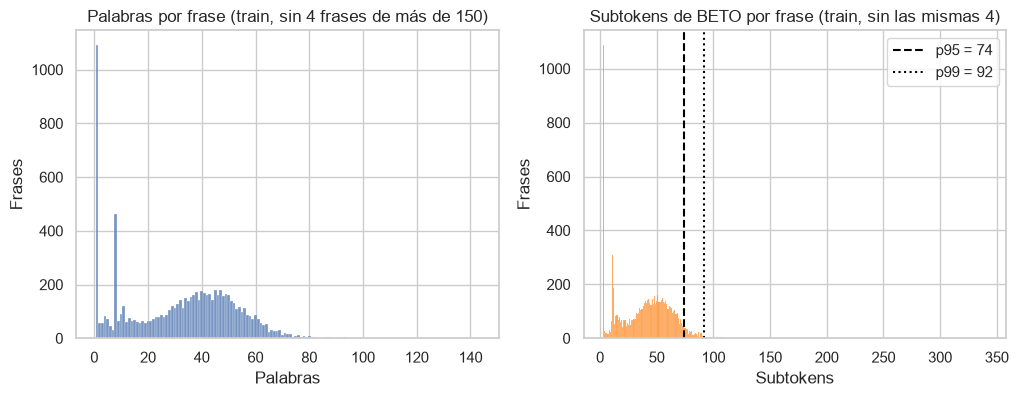

In [ ]:
# Longitud de las frases en palabras y en subtokens de BETO (solo el tokenizer)
from transformers import AutoTokenizer

tok_ner = AutoTokenizer.from_pretrained(MODEL_ID)
for split, df in df_ner.items():
    df = df[df["tokens"].map(len) > 0].copy()  # quito la frase vacía de cada split
    df["palabras"] = df["tokens"].map(len)
    # Las palabras ya vienen separadas: is_split_into_words=True. Cuenta [CLS] y [SEP].
    ids = tok_ner(df["tokens"].tolist(), is_split_into_words=True, verbose=False)["input_ids"]
    df["subtokens"] = [len(x) for x in ids]
    df_ner[split] = df
train_ner = df_ner["train"]

display(tabla_longitudes(df_ner, ["palabras", "subtokens"]))
todos = pd.concat(df_ner.values())
print(f"Subtokens por palabra (sin [CLS] ni [SEP]): {(todos['subtokens'] - 2).sum() / todos['palabras'].sum():.2f}")
for limite in (64, 128, 256):
    print(f"Frases con más de {limite} subtokens (los tres splits): {(todos['subtokens'] > limite).sum()} ({(todos['subtokens'] > limite).mean():.2%})")

mas_larga = train_ner.loc[train_ner["palabras"].idxmax()]
print(f"\nLa frase más larga de train tiene {mas_larga['palabras']} palabras y "
      f"{len(entidades_bio(mas_larga['etiquetas']))} entidades. Empieza así:")
print(textwrap.shorten(" ".join(mas_larga["tokens"]), 250))

# En la gráfica dejo por fuera las pocas frases de más de 150 palabras para que se vea la forma
normales = train_ner[train_ner["palabras"] <= 150]
fuera = len(train_ner) - len(normales)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(normales["palabras"], discrete=True, ax=axes[0])
axes[0].set(title=f"Palabras por frase (train, sin {fuera} frases de más de 150)", xlabel="Palabras", ylabel="Frases")
sns.histplot(normales["subtokens"], discrete=True, ax=axes[1], color="tab:orange")
marcar_percentiles(axes[1], train_ner["subtokens"])
axes[1].set(title=f"Subtokens de BETO por frase (train, sin las mismas {fuera})", xlabel="Subtokens", ylabel="Frases")
guardar(fig, "t2_longitudes")
plt.show()

En train las frases tienen 32 palabras y 40 subtokens en promedio, y el 95 % tiene 74 subtokens o menos. BETO parte poco las palabras: 1.19 subtokens por palabra. Hay unas pocas frases muy largas, 38 pasan de 128 subtokens y 9 de 256. La más larga de train es en realidad una tabla de cotizaciones de la bolsa, con 1238 palabras, 3920 subtokens y 160 entidades. En validación la frase más larga tiene 381 subtokens y en test 289.

In [ ]:
# Cómo parte BETO las palabras de la frase de ejemplo: las etiquetas son por palabra,
# así que al entrenar hay que decidir qué etiqueta recibe cada subtoken.
cod = tok_ner(fila["tokens"], is_split_into_words=True)
subtokens = cod.tokens()
por_palabra = {}
for pos, w in enumerate(cod.word_ids()):
    if w is not None:
        por_palabra.setdefault(w, []).append(subtokens[pos])
partidas = pd.DataFrame(
    {"palabra": fila["tokens"], "subtokens": [" ".join(por_palabra[i]) for i in range(len(fila["tokens"]))], "ner": fila["etiquetas"]}
)
display(partidas[partidas["subtokens"].str.contains(" ")])

,palabra,subtokens,ner
0,Ecuality,Ecu ##ali ##ty,B-ORG
13,Alcosto,Al ##cos ##to,B-MISC
22,Superoferta.com,Super ##of ##erta . com,B-MISC


En la frase de ejemplo, las únicas palabras que BETO parte son las entidades, que son nombres poco comunes: Ecuality queda como `Ecu ##ali ##ty` y Superoferta.com en cinco subtokens. Si le pongo la etiqueta solo al primer subtoken, `Ecu` recibe B-ORG y `##ali` y `##ty` quedan por fuera de la pérdida.

#### Qué implica para el entrenamiento

- max_length: en train uso `max_length=256`, que corta solo 9 frases de los tres splits (0.08 %), entre ellas la tabla de la bolsa. En validación y test no quiero dejar palabras sin predicción, así que ahí uso 512, el máximo de BETO, que alcanza para la frase más larga de cada split (381 y 289 subtokens). Con padding dinámico (`DataCollatorForTokenClassification`) el costo depende de la longitud real de cada batch, que en promedio es de 40 subtokens por frase.
- Etiquetas por subtoken: le pongo la etiqueta de la palabra al primer subtoken y -100 al resto, para que no cuenten ni en la pérdida ni en la evaluación. Con 1.19 subtokens por palabra, casi todas las palabras quedan con un solo subtoken.
- Limpieza: quito la frase vacía de cada split antes de tokenizar. Las tres etiquetas I- sin B- las dejo, porque seqeval las toma como inicio de entidad.
- Métrica: F1 de seqeval a nivel de entidad. Con 87.6 % de tokens O, un modelo que siempre diga O tendría 87.6 % de accuracy por token sin encontrar ninguna entidad. seqeval cuenta una entidad como acierto solo si el tipo y los límites coinciden con la referencia, que es como se evaluó el shared task. También reporto precisión, recall y F1 por tipo, para ver cómo le va a MISC, que es el tipo más escaso y el más variado. Mi punto de comparación es el 88.43 de F1 que reporta BETO en validación.
- Desbalance entre tipos: no uso pesos por clase. ORG tiene 3.4 veces más entidades que MISC, una diferencia moderada, y con el F1 por tipo veo si alguno se queda atrás.

### 2.3 Búsqueda de hiperparámetros

Primero preparo los datos como quedó en el EDA. Quito la frase vacía de cada split y tokenizo las frases, que ya vienen separadas en palabras (`is_split_into_words=True`), con `max_length=256` en train y 512 en validación y test. La etiqueta de cada palabra va en su primer subtoken; los demás subtokens, `[CLS]` y `[SEP]` llevan -100, el valor que la pérdida ignora. El padding lo hace `DataCollatorForTokenClassification` en cada batch, y también rellena las etiquetas con -100. La segunda celda muestra cómo quedan las etiquetas de la frase de ejemplo del EDA después de tokenizar.

El modelo es BETO con una capa lineal nueva que le da a cada subtoken un puntaje para cada una de las 9 etiquetas BIO. Como en la tarea 1, fijo la semilla antes de crearlo para que todas las corridas arranquen igual. Para calcular las métricas vuelvo a una etiqueta por palabra: me quedo solo con las posiciones que no tienen -100, que son los primeros subtokens, y se las paso a seqeval como una lista de etiquetas BIO por frase. Uso seqeval en su modo por defecto, que evalúa como el script de CoNLL: un I- sin B- antes también abre una entidad.

Los parámetros de esta tarea llevan `_T2` en el nombre (`REENTRENAR_T2`, `EPOCAS_FINAL_T2`, etc.) para no pisar los de la tarea 1 si vuelvo a correr alguna celda de allá. En la prueba rápida quedan 200 frases de train y 100 de validación y de test, todas de 40 palabras o menos para que el entrenamiento de BETO quepa en la memoria de mi Mac.

In [ ]:
# Tarea 2: configuración del fine-tuning y datos tokenizados
from seqeval import metrics as seqeval
from transformers import AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification, set_seed

# BETO solo tiene pytorch_model.bin en el Hub. Al cargarlo, transformers le pide en segundo plano a un
# Space del Hub que lo convierta a safetensors (abre un PR en el repo del modelo si no hay uno). No lo necesito.
os.environ["DISABLE_SAFETENSORS_CONVERSION"] = "1"

REENTRENAR_T2 = False  # True para repetir la búsqueda, el entrenamiento y el test aunque ya estén guardados
T2_DIR = RESULTADOS_DIR / "tarea2"
T2_DIR.mkdir(parents=True, exist_ok=True)

MAX_LENGTH_TRAIN_T2 = 256  # del EDA: solo 9 frases de los tres splits pasan de 256 subtokens
MAX_LENGTH_EVAL_T2 = 512  # el máximo de BETO: no corta ninguna frase de validación (381) ni de test (289)
LEARNING_RATES_T2 = [1e-5, 2e-5, 3e-5, 5e-5, 8e-5, 1e-4]  # 8e-5 y 1e-4 por si el mejor queda en el borde de arriba
EPOCAS_BUSQUEDA_T2 = 3
EPOCAS_FINAL_T2 = 4
N_BUSQUEDA_T2 = 80 if MODO_RAPIDO else 2000  # frases al azar del train para la búsqueda
F1_BETO_VAL = 0.8843  # F1 de NER en conll2002 que reporta la card de BETO, medido en validación
TIPOS_NER = ["PER", "ORG", "LOC", "MISC"]

tok_t2 = AutoTokenizer.from_pretrained(MODEL_ID)
colador_t2 = DataCollatorForTokenClassification(tok_t2)  # padding por batch; las etiquetas se rellenan con -100


def tokenizar_t2(batch, max_length):
    """Tokeniza frases ya separadas en palabras y pone la etiqueta de cada palabra en su primer subtoken."""
    cod = tok_t2(batch["tokens"], is_split_into_words=True, truncation=True, max_length=max_length)
    etiquetas = []
    for i, tags in enumerate(batch["ner_tags"]):
        anterior, etiquetas_frase = None, []
        for palabra in cod.word_ids(batch_index=i):
            # -100 en [CLS], [SEP] y en los subtokens que no son el primero de su palabra
            etiquetas_frase.append(-100 if palabra is None or palabra == anterior else tags[palabra])
            anterior = palabra
        etiquetas.append(etiquetas_frase)
    cod["labels"] = etiquetas
    return cod


def recortar_t2(ds, n):
    """Como recortar(), pero en la prueba rápida solo con frases de 40 palabras o menos, para que BETO quepa en la memoria del Mac."""
    return recortar(ds.filter(lambda ej: len(ej["tokens"]) <= 40) if MODO_RAPIDO else ds, n)


ds_t2 = ds_ner.filter(lambda ej: len(ej["tokens"]) > 0)  # sin la frase vacía de cada split
train_t2 = recortar_t2(ds_t2["train"], 200).map(tokenizar_t2, batched=True, fn_kwargs={"max_length": MAX_LENGTH_TRAIN_T2})
val_t2 = recortar_t2(ds_t2["validation"], 100).map(tokenizar_t2, batched=True, fn_kwargs={"max_length": MAX_LENGTH_EVAL_T2})
test_t2 = recortar_t2(ds_t2["test"], 100).map(tokenizar_t2, batched=True, fn_kwargs={"max_length": MAX_LENGTH_EVAL_T2})
muestra_t2 = train_t2.shuffle(seed=SEED).select(range(min(N_BUSQUEDA_T2, len(train_t2))))


def modelo_t2():
    """BETO con una capa nueva de 9 etiquetas BIO por subtoken. La semilla fija sus pesos iniciales."""
    set_seed(SEED)
    return AutoModelForTokenClassification.from_pretrained(
        MODEL_ID,
        num_labels=len(ETIQUETAS_NER),
        id2label=dict(enumerate(ETIQUETAS_NER)),
        label2id={etiqueta: i for i, etiqueta in enumerate(ETIQUETAS_NER)},
    )


def etiquetas_por_palabra(logits, label_ids):
    """Una etiqueta por palabra: solo las posiciones sin -100, que son el primer subtoken de cada palabra."""
    pred = np.asarray(logits).argmax(-1)
    reales, predichas = [], []
    for fila_pred, fila_real in zip(pred, label_ids):
        palabras = fila_real != -100
        reales.append([ETIQUETAS_NER[i] for i in fila_real[palabras]])
        predichas.append([ETIQUETAS_NER[i] for i in fila_pred[palabras]])
    return reales, predichas


def metricas_seqeval(reales, predichas):
    # zero_division=0: si el modelo no marca ninguna entidad, la precisión cuenta como 0
    return {
        "f1": seqeval.f1_score(reales, predichas, zero_division=0),
        "precision": seqeval.precision_score(reales, predichas, zero_division=0),
        "recall": seqeval.recall_score(reales, predichas, zero_division=0),
    }


def metricas_t2(pred):
    return metricas_seqeval(*etiquetas_por_palabra(pred.predictions, pred.label_ids))


print(f"Resultados de la tarea 2 en {ruta(T2_DIR)}")
tamanos = {"train": train_t2, "muestra para la búsqueda": muestra_t2, "validation": val_t2, "test": test_t2}
display(pd.DataFrame({"frases": {nombre: len(ds) for nombre, ds in tamanos.items()}}).T)
cortadas = sum(
    sum(e != -100 for e in etiquetas) < len(palabras)
    for etiquetas, palabras in zip(train_t2["labels"], train_t2["tokens"])
)
print(f"Frases de train que pierden palabras por el corte en {MAX_LENGTH_TRAIN_T2} subtokens: {cortadas}")

In [ ]:
# La frase de ejemplo del EDA (fila) después de tokenizar: la etiqueta queda solo en el primer subtoken
ejemplo_t2 = tokenizar_t2(
    {"tokens": [fila["tokens"]], "ner_tags": [[ETIQUETAS_NER.index(e) for e in fila["etiquetas"]]]},
    max_length=MAX_LENGTH_TRAIN_T2,
)
display(pd.DataFrame({
    "subtoken": tok_t2.convert_ids_to_tokens(ejemplo_t2["input_ids"][0]),
    "etiqueta": [ETIQUETAS_NER[i] if i != -100 else "-100" for i in ejemplo_t2["labels"][0]],
}).T)

La búsqueda es solo sobre el learning rate, como quedó en `docs/seleccion_datasets.md`: 1e-5, 2e-5, 3e-5, 5e-5, 8e-5 y 1e-4 con batch 16 y 3 épocas, sobre 2000 frases del train tomadas al azar. Agrego 8e-5 y 1e-4 porque en la tarea 1 ganó 5e-5, el borde superior de la grilla original, y aquí los 375 pasos son comparables a los de aquella búsqueda. Así pruebo si un learning rate más alto mejora el F1. No estratifico como en la tarea 1 porque aquí cada frase puede tener entidades de varios tipos. Cada corrida se evalúa con la validación completa y escojo el learning rate con mejor F1 general de seqeval al final de la tercera época. Ese F1 es el micro: junta las entidades de todos los tipos, y una entidad solo cuenta como acierto si el tipo y los límites coinciden con la referencia. El modelo de partida, la semilla y las frases son iguales en todas las corridas.

Como en la tarea 1, la tabla se guarda después de cada learning rate: si Colab se cae a mitad o si agrego valores a la lista, al volver a correr la celda solo entrena los que faltan. Después muestro la tabla ordenada por F1 y una gráfica del F1 contra el learning rate.

In [ ]:
# Búsqueda de learning rate sobre las frases de la muestra, sin checkpoints
archivo_busqueda_t2 = T2_DIR / "busqueda_lr.csv"
filas = pd.read_csv(archivo_busqueda_t2).to_dict("records") if archivo_busqueda_t2.exists() and not REENTRENAR_T2 else []
hechos = {fila["learning_rate"] for fila in filas}
if hechos:
    print(f"Cargo de {ruta(archivo_busqueda_t2)} los learning rates ya probados: "
          f"{', '.join(f'{lr:g}' for lr in sorted(hechos))} (REENTRENAR_T2 = True para repetirlos)")

for lr in [lr for lr in LEARNING_RATES_T2 if lr not in hechos]:
    print(f"--- learning rate {lr:g}")
    trainer = Trainer(
        model=modelo_t2(),
        args=argumentos(CHECKPOINTS_DIR / "t2_busqueda", learning_rate=lr, num_train_epochs=EPOCAS_BUSQUEDA_T2),
        train_dataset=muestra_t2,
        eval_dataset=val_t2,
        processing_class=tok_t2,
        data_collator=colador_t2,
        compute_metrics=metricas_t2,
    )
    historial, velocidad = entrenar(trainer)
    ultima = historial.iloc[-1]  # la última época
    filas.append({
        "learning_rate": lr,
        "f1": ultima["f1"],
        "precision": ultima["precision"],
        "recall": ultima["recall"],
        "loss_val": ultima["loss_val"],
        "loss_train": ultima["loss_train"],
        "frases": len(muestra_t2),
        **velocidad,
    })
    pd.DataFrame(filas).to_csv(archivo_busqueda_t2, index=False)  # por si Colab se cae a mitad
    del trainer
    liberar_memoria()

busqueda_t2 = pd.DataFrame(filas).sort_values("f1", ascending=False, ignore_index=True)
shutil.rmtree(CHECKPOINTS_DIR / "t2_busqueda", ignore_errors=True)  # el Trainer crea la carpeta aunque no guarde
aviso_prueba_rapida()
display(busqueda_t2.round(4).assign(learning_rate=busqueda_t2["learning_rate"].map("{:g}".format)))
print(f"Tiempo total de la búsqueda: {busqueda_t2['segundos_entrenamiento'].sum():.0f} s")

In [ ]:
# F1 de seqeval en validación contra learning rate
orden = busqueda_t2.sort_values("learning_rate")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(orden["learning_rate"], orden["f1"], marker="o")
for lr, f1 in zip(orden["learning_rate"], orden["f1"]):
    ax.annotate(f"{f1:.3f}", (lr, f1), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xscale("log")
ax.set_xticks(orden["learning_rate"], [f"{lr:g}" for lr in orden["learning_rate"]])
ax.set_xticks([], minor=True)
ax.set(
    title=titulo(f"Búsqueda de learning rate ({len(muestra_t2)} frases, {EPOCAS_BUSQUEDA_T2} épocas)"),
    xlabel="Learning rate (escala logarítmica)",
    ylabel="F1 de seqeval en validación",
)
guardar(fig, "t2_busqueda_lr", carpeta=FIG_ENTRENAMIENTO_DIR)
plt.show()

### 2.4 Entrenamiento con la data completa

El learning rate sale de la primera fila de la tabla de 2.3, que está ordenada por F1. Entreno con las 8323 frases del train (todas menos la vacía) durante 4 épocas, el máximo que sugiere el paper de BERT, y evalúo en validación al final de cada una. Al terminar, el Trainer carga la época con mejor F1 (`load_best_model_at_end`) y la guardo con su tokenizer en `OUTPUT_DIR/tarea2/modelo`, junto con el historial por época y el tiempo de entrenamiento. Igual que en la tarea 1, si el modelo guardado se entrenó con otro learning rate o con otro número de épocas, la celda lo entrena de nuevo sola.

En las gráficas reviso si la loss de validación sube mientras la de train sigue bajando y en qué época deja de mejorar el F1. En la del F1 marco como referencia el 88.43 que reporta la card de BETO en validación.

In [ ]:
# Entrenamiento con todo el train y el mejor learning rate de 2.3
MEJOR_LR_T2 = float(busqueda_t2.loc[0, "learning_rate"])  # la tabla está ordenada por F1
dir_modelo_t2 = T2_DIR / "modelo"
archivo_historial_t2 = T2_DIR / "historial_entrenamiento.csv"
archivo_entrenamiento_t2 = T2_DIR / "entrenamiento.json"  # se escribe al final: si existe, todo terminó

# Reuso el modelo guardado solo si se entrenó con el learning rate y las épocas de ahora
info_t2 = cargar_si_vigente(archivo_entrenamiento_t2, {"learning_rate": MEJOR_LR_T2, "epocas": EPOCAS_FINAL_T2}, REENTRENAR_T2)
if info_t2 is not None:
    historial_t2 = pd.read_csv(archivo_historial_t2)
    print(f"Cargo el entrenamiento guardado en {ruta(T2_DIR)} (REENTRENAR_T2 = True para repetirlo).")
else:
    ckpt_t2 = CHECKPOINTS_DIR / "tarea2"
    trainer = Trainer(
        model=modelo_t2(),
        args=argumentos(
            ckpt_t2,
            learning_rate=MEJOR_LR_T2,
            num_train_epochs=EPOCAS_FINAL_T2,
            save_strategy="best",  # checkpoint solo cuando mejora el F1 de validación
            save_only_model=True,  # solo los pesos, sin el estado del optimizador
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="f1",
        ),
        train_dataset=train_t2,
        eval_dataset=val_t2,
        processing_class=tok_t2,
        data_collator=colador_t2,
        compute_metrics=metricas_t2,
    )
    print(f"learning rate {MEJOR_LR_T2:g}, {len(train_t2)} frases, {EPOCAS_FINAL_T2} épocas")
    historial_t2, velocidad = entrenar(trainer)
    trainer.save_model(dir_modelo_t2)  # el de la mejor época, con su tokenizer
    historial_t2.to_csv(archivo_historial_t2, index=False)
    mejor = historial_t2.loc[historial_t2["f1"].idxmax()]
    info_t2 = {
        "learning_rate": MEJOR_LR_T2,
        "epocas": EPOCAS_FINAL_T2,
        "mejor_epoca": int(mejor["época"]),
        "f1_val": float(mejor["f1"]),
        "frases_train": len(train_t2),
        **velocidad,
    }
    guardar_json(info_t2, archivo_entrenamiento_t2)
    shutil.rmtree(ckpt_t2, ignore_errors=True)  # el modelo final ya quedó guardado
    del trainer
    liberar_memoria()

aviso_prueba_rapida()
display(historial_t2.round(4))
print(f"Mejor época: {info_t2['mejor_epoca']} (F1 {info_t2['f1_val']:.4f}), guardada en {ruta(dir_modelo_t2)}")
print(f"Entrenamiento: {info_t2['segundos_entrenamiento']} s, {info_t2['muestras_por_segundo']} muestras/s")

In [ ]:
# Loss de train y validación, y F1 de validación por época
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas = historial_t2["época"]
axes[0].plot(epocas, historial_t2["loss_train"], marker="o", label="train")
axes[0].plot(epocas, historial_t2["loss_val"], marker="o", label="validación")
axes[0].set(title=titulo("Loss por época"), xlabel="Época", ylabel="Loss (entropía cruzada)", xticks=epocas)
axes[0].legend()
axes[1].plot(epocas, historial_t2["f1"], marker="o", color="tab:green", label="validación")
axes[1].axhline(F1_BETO_VAL, color="gray", linestyle="--", label=f"card de BETO ({F1_BETO_VAL})")
axes[1].axvline(info_t2["mejor_epoca"], color="gray", linestyle=":", label=f"mejor época ({info_t2['mejor_epoca']})")
axes[1].set(title=titulo("F1 de seqeval por época"), xlabel="Época", ylabel="F1 (entidades)", xticks=epocas)
axes[1].legend()
guardar(fig, "t2_entrenamiento", carpeta=FIG_ENTRENAMIENTO_DIR)
plt.show()

### 2.5 Evaluación del mejor modelo

Igual que en la tarea 1, cargo el modelo desde su carpeta y predigo con él la validación y el test. El test se evalúa una sola vez: las predicciones y las métricas se guardan junto con el learning rate y las épocas del modelo, y si vuelvo a correr la celda las carga. Solo predice de nuevo si el modelo de 2.4 cambió. Las predicciones vuelven a una etiqueta por palabra antes de calcular las métricas. Con `max_length=512` no se corta ninguna frase de validación ni de test, así que todas las palabras tienen predicción, y la celda comprueba que las etiquetas que quedan al quitar los -100 son las mismas del dataset. El F1 de validación tiene que coincidir con el de la mejor época de 2.4.

In [ ]:
# Predicciones del modelo guardado en validación y test, una etiqueta por palabra (el test se evalúa una sola vez)
archivo_pred_t2 = T2_DIR / "predicciones.jsonl"
archivo_metricas_t2 = T2_DIR / "metricas_val_test.json"
# Con qué modelo salen las predicciones. Si el de 2.4 cambia, las guardadas ya no le corresponden.
config_modelo_t2 = {k: info_t2[k] for k in ("learning_rate", "epocas", "mejor_epoca")}

guardadas_t2 = cargar_si_vigente(archivo_metricas_t2, config_modelo_t2, REENTRENAR_T2)
if guardadas_t2 is not None:
    pred_t2 = pd.DataFrame([json.loads(linea) for linea in archivo_pred_t2.read_text(encoding="utf-8").splitlines()])
    print(f"Cargo las predicciones guardadas en {ruta(archivo_pred_t2)}: el test no se vuelve a evaluar.")
else:
    modelo_final_t2 = AutoModelForTokenClassification.from_pretrained(dir_modelo_t2)
    tok_final_t2 = AutoTokenizer.from_pretrained(dir_modelo_t2)
    evaluador = Trainer(
        model=modelo_final_t2,
        args=argumentos(CHECKPOINTS_DIR / "t2_evaluacion", eval_strategy="no"),
        processing_class=tok_final_t2,
        data_collator=DataCollatorForTokenClassification(tok_final_t2),
    )
    partes = []
    for split, ds in [("validation", val_t2), ("test", test_t2)]:
        salida = evaluador.predict(ds)
        reales, predichas = etiquetas_por_palabra(salida.predictions, salida.label_ids)
        # Ninguna frase se cortó, así que cada palabra tiene su etiqueta y su predicción
        assert reales == [[ETIQUETAS_NER[i] for i in tags] for tags in ds["ner_tags"]], "no coinciden con el dataset"
        partes.append(pd.DataFrame({
            "split": split,
            "id": list(ds["id"]),
            "tokens": list(ds["tokens"]),
            "real": reales,
            "pred": predichas,
        }))
    pred_t2 = pd.concat(partes, ignore_index=True)
    guardadas_t2 = config_modelo_t2 | {
        split: metricas_seqeval(list(grupo["real"]), list(grupo["pred"])) for split, grupo in pred_t2.groupby("split")
    }
    archivo_pred_t2.write_text(
        "".join(json.dumps(fila_pred, ensure_ascii=False) + "\n" for fila_pred in pred_t2.to_dict("records")),
        encoding="utf-8",
    )
    guardar_json(guardadas_t2, archivo_metricas_t2)
    print(f"Predicciones guardadas en {ruta(archivo_pred_t2)} y métricas en {ruta(archivo_metricas_t2)}")
    del evaluador, modelo_final_t2
    shutil.rmtree(CHECKPOINTS_DIR / "t2_evaluacion", ignore_errors=True)
    liberar_memoria()

metricas_finales_t2 = {split: guardadas_t2[split] for split in ("validation", "test")}
pred_val_t2 = pred_t2[pred_t2["split"] == "validation"]
pred_test_t2 = pred_t2[pred_t2["split"] == "test"]
print(f"Modelo: lr {config_modelo_t2['learning_rate']:g}, mejor época {config_modelo_t2['mejor_epoca']} de {config_modelo_t2['epocas']}")

Reporto precisión, recall y F1 de seqeval en validación y en test, en general y por tipo de entidad. La precisión es la fracción de las entidades que marcó el modelo que coinciden en tipo y límites con la referencia, y el recall, la fracción de las entidades de la referencia que el modelo encontró. En el reporte por tipo, `micro avg` es el F1 general y `support` es el número de entidades de la referencia.

In [ ]:
# Precisión, recall y F1 de seqeval en validación y test, en general y por tipo de entidad
def reporte_por_tipo(pred):
    reporte = seqeval.classification_report(list(pred["real"]), list(pred["pred"]), output_dict=True, zero_division=0)
    reporte = pd.DataFrame(reporte).T.rename(columns={"f1-score": "f1"})
    reporte["support"] = reporte["support"].astype(int)
    return reporte.reindex([t for t in [*TIPOS_NER, "micro avg", "macro avg", "weighted avg"] if t in reporte.index])


aviso_prueba_rapida()
display(pd.DataFrame(metricas_finales_t2).T.loc[["validation", "test"], ["precision", "recall", "f1"]].round(4))
print(f"F1 de la mejor época en 2.4: {info_t2['f1_val']:.4f} (tiene que coincidir con validation)")

reporte_val_t2 = reporte_por_tipo(pred_val_t2)
reporte_test_t2 = reporte_por_tipo(pred_test_t2)
display(pd.concat({"validation": reporte_val_t2, "test": reporte_test_t2}, axis=1).round(3))

Después comparo dos cosas. La primera es mi F1 de validación contra el 88.43 que reporta la card de BETO, que también es sobre validación; para test la card no da ninguna cifra. La segunda es validación contra test, por tipo de entidad. En el EDA vi que validación tiene más PER y test más LOC que train, y como el F1 general junta las entidades de todos los tipos, cada split pesa los tipos distinto. Por eso pongo al lado del F1 de cada tipo qué porcentaje de las entidades de cada split es de ese tipo.

In [ ]:
# Mi F1 de validación contra el de la card de BETO, y validación contra test por tipo de entidad
aviso_prueba_rapida()
f1_val_t2 = metricas_finales_t2["validation"]["f1"]
f1_test_t2 = metricas_finales_t2["test"]["f1"]
display(pd.DataFrame({"F1 en validación": {"BETO (card del modelo)": F1_BETO_VAL, "mi modelo": f1_val_t2}}).round(4))
print(f"Mi modelo contra la card: {100 * (f1_val_t2 - F1_BETO_VAL):+.2f} puntos de F1")
print(f"F1 general: validación {f1_val_t2:.4f}, test {f1_test_t2:.4f} ({100 * (f1_test_t2 - f1_val_t2):+.2f} puntos)")

tipos = [t for t in TIPOS_NER if t in reporte_val_t2.index and t in reporte_test_t2.index]
soporte_val, soporte_test = reporte_val_t2.loc[tipos, "support"], reporte_test_t2.loc[tipos, "support"]
por_tipo_t2 = pd.DataFrame({
    "F1 validación": reporte_val_t2.loc[tipos, "f1"],
    "F1 test": reporte_test_t2.loc[tipos, "f1"],
    "% de las entidades en validación": 100 * soporte_val / soporte_val.sum(),
    "% de las entidades en test": 100 * soporte_test / soporte_test.sum(),
})
por_tipo_t2.insert(2, "test - validación", por_tipo_t2["F1 test"] - por_tipo_t2["F1 validación"])
display(por_tipo_t2.round(3).round({"% de las entidades en validación": 1, "% de las entidades en test": 1}))

fig, ax = plt.subplots(figsize=(8, 4))
largo = (
    por_tipo_t2[["F1 validación", "F1 test"]]
    .reset_index(names="tipo")
    .melt(id_vars="tipo", var_name="split", value_name="F1")
)
sns.barplot(data=largo, x="tipo", y="F1", hue="split", ax=ax)
ax.set(title=titulo("F1 de seqeval por tipo de entidad"), xlabel="Tipo de entidad", ylabel="F1", ylim=(0, 1))
guardar(fig, "t2_f1_por_tipo", carpeta=FIG_ENTRENAMIENTO_DIR)
plt.show()

Para ver qué errores comete el modelo comparo entidad por entidad en test. Cada entidad de la referencia que el modelo no acierta exacta cae en uno de cuatro grupos:

- tipo equivocado: el modelo marcó las mismas palabras, pero con otro tipo
- límites mal puestos: el modelo marcó una entidad del mismo tipo que se cruza con la real, pero empieza o termina en otra palabra
- tipo y límites: se cruza con una entidad del modelo que tiene otro tipo y otros límites
- no encontrada: el modelo no marcó ninguna de esas palabras como entidad

Aparte cuento las entidades que el modelo marcó donde la referencia no tiene ninguna. Después muestro hasta tres frases de ejemplo de los tipos equivocados, de los límites mal puestos y de las entidades no encontradas, escogidas al azar entre las de 40 palabras o menos para que se puedan leer. Las entidades van entre corchetes como en el EDA: primero la referencia y debajo lo que marcó el modelo.

In [ ]:
# Errores en test, entidad por entidad
def errores_frase(tokens, real, pred):
    """Clasifica las entidades de la referencia que el modelo no acertó exactas, y las que marcó de más."""
    texto = lambda inicio, fin: " ".join(tokens[inicio:fin])
    ents_real, ents_pred = set(entidades_bio(real)), set(entidades_bio(pred))
    errores = []
    for tipo, a, b in sorted(ents_real - ents_pred, key=lambda e: e[1]):
        cruces = sorted([(t, i, f) for t, i, f in ents_pred if i < b and a < f], key=lambda e: e[1])
        if any((i, f) == (a, b) for _, i, f in cruces):
            error = "tipo equivocado"
        elif any(t == tipo for t, _, _ in cruces):
            error = "límites mal puestos"
        elif cruces:
            error = "tipo y límites"
        else:
            error = "no encontrada"
        errores.append({
            "error": error,
            "tipo real": tipo,
            "referencia": f"{tipo} {texto(a, b)}",
            "tipo modelo": ", ".join(t for t, _, _ in cruces) or "-",
            "modelo": "; ".join(f"{t} {texto(i, f)}" for t, i, f in cruces) or "-",
        })
    for tipo, i, f in sorted(ents_pred - ents_real, key=lambda e: e[1]):
        if not any(a < f and i < b for _, a, b in ents_real):
            errores.append({"error": "sobrante", "tipo real": "-", "referencia": "-",
                            "tipo modelo": tipo, "modelo": f"{tipo} {texto(i, f)}"})
    return errores


errores_t2 = pd.DataFrame(
    [
        {"frase": indice, **error}
        for indice, frase in pred_test_t2.iterrows()
        for error in errores_frase(frase["tokens"], frase["real"], frase["pred"])
    ],
    columns=["frase", "error", "tipo real", "referencia", "tipo modelo", "modelo"],
)
GRUPOS_ERROR = ["tipo equivocado", "límites mal puestos", "tipo y límites", "no encontrada", "sobrante"]

aviso_prueba_rapida()
print(f"Entidades en la referencia de test: {sum(len(entidades_bio(r)) for r in pred_test_t2['real'])}")
display(errores_t2["error"].value_counts().reindex(GRUPOS_ERROR, fill_value=0).rename("entidades").to_frame())

tipo_mal = errores_t2[errores_t2["error"] == "tipo equivocado"]
if len(tipo_mal):
    print("Tipo equivocado: tipo de la referencia (filas) contra el que puso el modelo (columnas)")
    display(pd.crosstab(tipo_mal["tipo real"], tipo_mal["tipo modelo"]))
print("No encontradas, por tipo de la referencia:")
display(errores_t2.loc[errores_t2["error"] == "no encontrada", "tipo real"].value_counts().rename("entidades").to_frame())

In [ ]:
# Frases de ejemplo de tres grupos de errores: arriba la referencia y abajo lo que marcó el modelo
aviso_prueba_rapida()
cortas = errores_t2["frase"].map(lambda i: len(pred_test_t2.loc[i, "tokens"]) <= 40)
for grupo_error in ["tipo equivocado", "límites mal puestos", "no encontrada"]:
    grupo = errores_t2[(errores_t2["error"] == grupo_error) & cortas]
    print(f"===== {grupo_error} ({(errores_t2['error'] == grupo_error).sum()} en test)\n")
    for _, error in grupo.sample(min(3, len(grupo)), random_state=SEED).iterrows():
        frase = pred_test_t2.loc[error["frase"]]
        print(f"referencia: {error['referencia']}  |  modelo: {error['modelo']}")
        print(textwrap.fill(marcar_entidades(frase["tokens"], frase["real"]), 130, initial_indent="  real:   ", subsequent_indent=" " * 10))
        print(textwrap.fill(marcar_entidades(frase["tokens"], frase["pred"]), 130, initial_indent="  modelo: ", subsequent_indent=" " * 10))
        print()

Para terminar, una demo con `pipeline("token-classification")` sobre frases que escribí yo, sobre Medellín, la Universidad de Antioquia y otros temas de Colombia. Uso `aggregation_strategy="first"`: cada palabra toma la etiqueta de su primer subtoken, que es como entrené, y después las palabras seguidas del mismo tipo se juntan en una entidad. La columna "esperadas" tiene las entidades que yo marcaría; no vienen del dataset.

In [ ]:
# Demo con pipeline sobre frases nuevas, agrupando los subtokens en entidades
from transformers import pipeline

etiquetador_t2 = pipeline("token-classification", model=str(dir_modelo_t2), aggregation_strategy="first", device=DEVICE)
frases_t2 = {
    "La Universidad de Antioquia abrió las inscripciones para el próximo semestre en Medellín.":
        "ORG Universidad de Antioquia; LOC Medellín",
    "La profesora Ana María Restrepo viajó de Medellín a Madrid para presentar su tesis en la Universidad Complutense.":
        "PER Ana María Restrepo; LOC Medellín; LOC Madrid; ORG Universidad Complutense",
    "Atlético Nacional le ganó al Independiente Medellín en el estadio Atanasio Girardot.":
        "ORG Atlético Nacional; ORG Independiente Medellín; LOC Atanasio Girardot",
    "Cada agosto, la Feria de las Flores llena de turistas las calles de Medellín.":
        "MISC Feria de las Flores; LOC Medellín",
    "El Metro de Medellín y Empresas Públicas de Medellín firmaron un convenio con la Gobernación de Antioquia.":
        "ORG Metro de Medellín; ORG Empresas Públicas de Medellín; ORG Gobernación de Antioquia",
    "Gabriel García Márquez nació en Aracataca y escribió Cien años de soledad.":
        "PER Gabriel García Márquez; LOC Aracataca; MISC Cien años de soledad",
}
salidas = etiquetador_t2(list(frases_t2))

aviso_prueba_rapida()
display(pd.DataFrame([
    {
        "frase": frase,
        "esperadas": esperadas,
        "modelo": "; ".join(f"{e['entity_group']} {e['word']} ({e['score']:.2f})" for e in entidades) or "-",
    }
    for (frase, esperadas), entidades in zip(frases_t2.items(), salidas)
]))

La última celda sube el modelo a mi cuenta de Hugging Face, igual que en la tarea 1: está apagada (`SUBIR_AL_HUB = False`), no sube el modelo de la prueba rápida y necesita un token con permiso de escritura.

In [ ]:
# Subir el modelo a mi cuenta de Hugging Face (apagado por defecto)
SUBIR_AL_HUB = False
NOMBRE_REPO_T2 = "bert-base-spanish-wwm-cased-conll2002-proyecto2"
REPO_PRIVADO = True  # lo cambio a False si quiero que sea público

if not SUBIR_AL_HUB:
    print("SUBIR_AL_HUB = False: no se sube nada.")
elif MODO_RAPIDO:
    print("Este es el modelo de la prueba rápida: no lo subo.")
else:
    repo_t2 = f"{whoami()['name']}/{NOMBRE_REPO_T2}"
    modelo_hub = AutoModelForTokenClassification.from_pretrained(dir_modelo_t2)
    tok_hub = AutoTokenizer.from_pretrained(dir_modelo_t2)
    mensaje = f"BETO ajustado en conll2002 es (lr {info_t2['learning_rate']:g}, época {info_t2['mejor_epoca']})"
    modelo_hub.push_to_hub(repo_t2, private=REPO_PRIVADO, commit_message=mensaje)
    tok_hub.push_to_hub(repo_t2, private=REPO_PRIVADO, commit_message="tokenizer")
    print(f"Subido a https://huggingface.co/{repo_t2}")

## Tarea 3: Sequence-to-sequence

Resumir diálogos en inglés con `bart-base`.

In [ ]:
# Tarea 3: constantes
DATASET_ID = "knkarthick/dialogsum"
MODEL_ID = "facebook/bart-base"

### 3.1 Descripción del dataset

El problema es resumir conversaciones: a partir de un diálogo entre dos o más personas, generar un resumen corto de lo que pasó. Sirve para resumir reuniones, llamadas de servicio al cliente o chats largos.

- Entrada: el diálogo completo (columna `dialogue`), en inglés, con un turno por línea y los hablantes marcados como `#Person1#`, `#Person2#`, etc.
- Salida: el resumen (columna `summary`), un texto libre escrito por una persona. También hay una columna `topic` con el tema en pocas palabras, que no uso como salida.
- Tipo de problema: sequence-to-sequence, en concreto resumen abstractivo. El modelo tiene que redactar el resumen con sus propias palabras.
- Tamaño: 12460 diálogos de train, 500 de validación y 1500 filas de test. El test tiene 500 diálogos con tres resúmenes cada uno, lo que cuadra con los 13460 diálogos que menciona la card (12460 + 500 + 500).
- Origen y anotación: según la card, los diálogos salen de tres corpus públicos (DailyDialog, DREAM y MuTual) y de una página para practicar inglés hablado. Son conversaciones cara a cara sobre temas cotidianos como estudio, trabajo, salud, compras o viajes. Los resúmenes los escribieron expertos en lenguaje siguiendo unas reglas: dar la información más importante, ser breves, conservar las entidades nombradas, escribir desde el punto de vista de un observador y usar lenguaje formal.
- Licencia: CC BY-NC-SA 4.0 (uso no comercial, citando la fuente y compartiendo con la misma licencia).
- Cita: Chen, Y., Liu, Y., Chen, L. y Zhang, Y. (2021). DialogSum: A Real-Life Scenario Dialogue Summarization Dataset. En *Findings of the Association for Computational Linguistics: ACL-IJCNLP 2021*, pp. 5062-5074. https://aclanthology.org/2021.findings-acl.449

El modelo es `facebook/bart-base`, un encoder-decoder de 139 M de parámetros preentrenado en inglés a reconstruir texto al que le dañaron partes. Es del tipo BART que pide el enunciado para seq2seq y, en la prueba que hice para escoger modelo, funciona en fp16 sin problemas.

In [ ]:
# Carga del dataset y tamaño de cada split
from datasets import load_dataset

ds_sum = load_dataset(DATASET_ID)
df_sum = {split: ds_sum[split].to_pandas() for split in ds_sum}

display(pd.DataFrame({
    "filas": {split: len(df) for split, df in df_sum.items()},
    "diálogos distintos": {split: df["dialogue"].nunique() for split, df in df_sum.items()},
}).T)
print("Columnas:", ds_sum["train"].column_names)

,train,validation,test
filas,12460,500,1500
diálogos distintos,12458,500,500


Columnas: ['id', 'dialogue', 'summary', 'topic']


### 3.2 Análisis exploratorio (EDA)

In [ ]:
# Un ejemplo del train: diálogo, resumen y tema
def mostrar_dialogo(dialogo, ancho=110):
    for linea in dialogo.splitlines():
        print(textwrap.fill(linea, ancho, subsequent_indent="    "))


train_sum = df_sum["train"]
# Uno de largo típico: entre 8 y 12 líneas
tipicos = train_sum[train_sum["dialogue"].str.count("\n").between(7, 11)]
ej = tipicos.sample(1, random_state=SEED).iloc[0]
mostrar_dialogo(ej["dialogue"])
print("\nResumen:", textwrap.fill(ej["summary"], 110))
print("Tema:", ej["topic"])

#Person1#: How is your new car?
#Person2#: Perfect. Couldn't be better.
#Person1#: Why do you say so? Can I see your new car?
#Person2#: Of course you can. ( Lead Carl to his garage. )
#Person1#: Wow, this new car is dynamite! It is a shiny, beautiful car.
#Person2#: My car is simply a daisy. It drives smoothly.
#Person1#: The car has very sleek lines. I love it.
#Person2#: I am glad to hear that. I'm really pleased with it.
#Person1#: You made a good choice.

Resumen: #Person2# says #Person2#'s new car is perfect and shows #Person1# the car. #Person1# likes it.
Tema: a new car


Cada turno empieza con el hablante (`#Person1#`, `#Person2#`). El resumen es mucho más corto que el diálogo, está escrito desde afuera, en tercera persona, y nombra a los participantes con las mismas etiquetas `#Person1#` y `#Person2#` porque el diálogo no dice sus nombres. A veces el diálogo trae acotaciones entre paréntesis, como "( Lead Carl to his garage. )".

media  p50  p95  p99   máx
train      tokens_dialogo  212.4  193  390  579  1429
           tokens_resumen   36.9   34   65   84   249
validation tokens_dialogo  209.6  191  380  507   726
           tokens_resumen   34.7   32   62   80   100
test       tokens_dialogo  217.5  200  394  521  1366
           tokens_resumen   30.0   28   51   69   104

Diálogos con más de 256 tokens: 3758 (25.99%)
Diálogos con más de 512 tokens: 215 (1.49%)
Diálogos con más de 1024 tokens: 12 (0.08%)
Resúmenes con más de 64 tokens: 659 (4.56%)
Resúmenes con más de 96 tokens: 65 (0.45%)
Resúmenes con más de 128 tokens: 13 (0.09%)


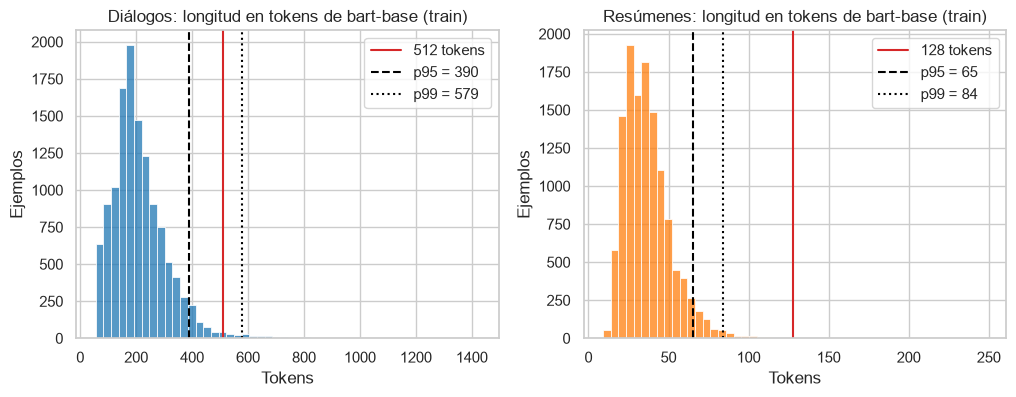

In [ ]:
# Longitud de diálogos y resúmenes en tokens de bart-base (solo el tokenizer)
from transformers import AutoTokenizer

tok_sum = AutoTokenizer.from_pretrained(MODEL_ID)
for df in df_sum.values():
    # Sin truncar y con <s> y </s>
    df["tokens_dialogo"] = [len(x) for x in tok_sum(df["dialogue"].tolist(), verbose=False)["input_ids"]]
    df["tokens_resumen"] = [len(x) for x in tok_sum(df["summary"].tolist(), verbose=False)["input_ids"]]
    df["compresion"] = df["tokens_resumen"] / df["tokens_dialogo"]

display(tabla_longitudes(df_sum, ["tokens_dialogo", "tokens_resumen"]))
todos = pd.concat(df_sum.values())
for limite in (256, 512, 1024):
    print(f"Diálogos con más de {limite} tokens: {(todos['tokens_dialogo'] > limite).sum()} ({(todos['tokens_dialogo'] > limite).mean():.2%})")
for limite in (64, 96, 128):
    print(f"Resúmenes con más de {limite} tokens: {(todos['tokens_resumen'] > limite).sum()} ({(todos['tokens_resumen'] > limite).mean():.2%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, titulo, color, limite in [
    (axes[0], "tokens_dialogo", "Diálogos", "tab:blue", 512),
    (axes[1], "tokens_resumen", "Resúmenes", "tab:orange", 128),
]:
    sns.histplot(train_sum[col], bins=50, ax=ax, color=color)
    ax.axvline(limite, color="tab:red", label=f"{limite} tokens")
    marcar_percentiles(ax, train_sum[col])
    ax.set(title=f"{titulo}: longitud en tokens de bart-base (train)", xlabel="Tokens", ylabel="Ejemplos")
guardar(fig, "t3_longitudes")
plt.show()

En train los diálogos tienen 212 tokens en promedio y los resúmenes 37. El 95 % de los diálogos tiene 390 tokens o menos, pero hay una cola larga: 215 diálogos de los tres splits (1.49 %) pasan de 512 tokens y 12 (0.08 %) pasan de 1024, que es lo máximo que acepta BART. De los resúmenes, solo 13 (0.09 %) pasan de 128 tokens. Los resúmenes del test son más cortos que los de train: 30 tokens en promedio contra 37.

,mean,std,min,5%,50%,95%,max
train,0.187,0.058,0.051,0.111,0.178,0.292,0.768
validation,0.179,0.061,0.069,0.105,0.169,0.272,0.776
test,0.154,0.056,0.031,0.085,0.142,0.268,0.448


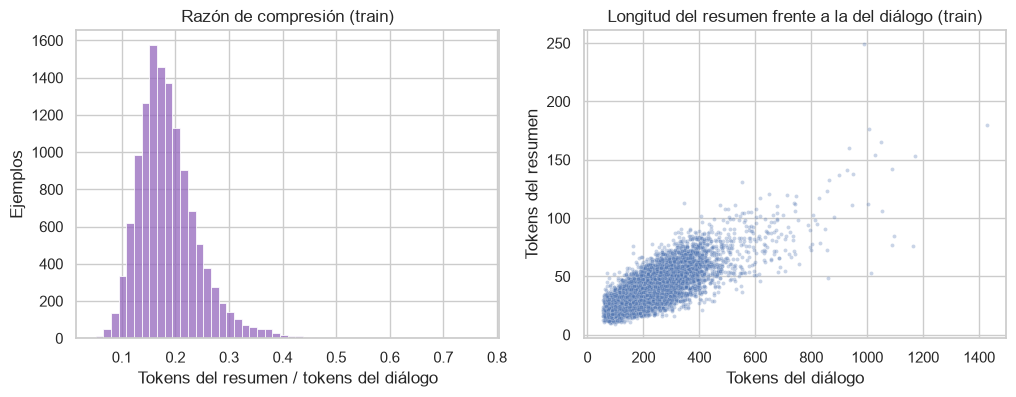

Correlación entre longitud del diálogo y del resumen (train): 0.79


In [ ]:
# Cuánto se comprime: tokens del resumen / tokens del diálogo
compresion = pd.DataFrame({split: df["compresion"].describe(percentiles=[0.05, 0.5, 0.95]) for split, df in df_sum.items()})
display(compresion.T.drop(columns="count").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_sum["compresion"], bins=50, ax=axes[0], color="tab:purple")
axes[0].set(title="Razón de compresión (train)", xlabel="Tokens del resumen / tokens del diálogo", ylabel="Ejemplos")
sns.scatterplot(data=train_sum, x="tokens_dialogo", y="tokens_resumen", s=8, alpha=0.3, ax=axes[1])
axes[1].set(title="Longitud del resumen frente a la del diálogo (train)", xlabel="Tokens del diálogo", ylabel="Tokens del resumen")
guardar(fig, "t3_compresion")
plt.show()
print(f"Correlación entre longitud del diálogo y del resumen (train): {train_sum['tokens_dialogo'].corr(train_sum['tokens_resumen']):.2f}")

El resumen ocupa más o menos el 18 % de los tokens del diálogo (mediana de 0.178 en train) y su longitud crece con la del diálogo (correlación de 0.79). En test la razón es menor (mediana de 0.142), lo que cuadra con que sus resúmenes sean más cortos.

,,media,p50,p95,p99,máx
train,turnos,9.5,9,16,23,61
validation,turnos,9.4,9,16,20,29
test,turnos,9.7,9,16,26,65


Diálogos de train según número de hablantes: {2: 12333, 3: 113, 4: 9, 5: 3, 6: 1, 7: 1}
Resúmenes de train que nombran a alguien como #PersonN#: 88.3%
Así tokeniza bart-base un turno: ['#', 'Person', '1', '#', ':', 'ĠHello', ',', 'Ġhow', 'Ġare', 'Ġyou', '?']


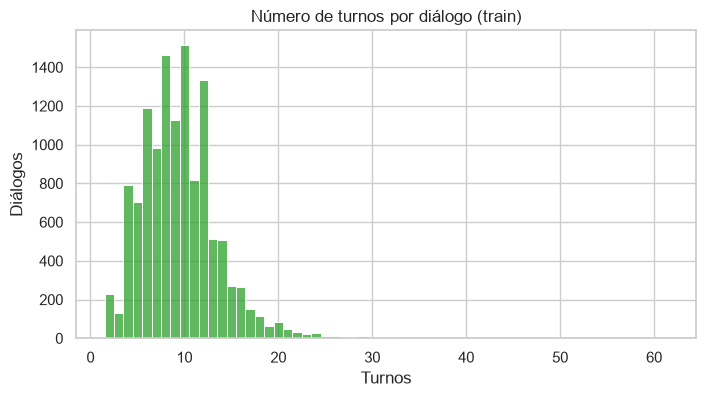

In [ ]:
# Turnos y hablantes por diálogo
for df in df_sum.values():
    df["turnos"] = df["dialogue"].map(lambda d: sum(l.strip().startswith("#Person") for l in d.splitlines()))
    df["hablantes"] = df["dialogue"].str.findall(r"#Person\d+#").map(lambda h: len(set(h)))

display(tabla_longitudes(df_sum, ["turnos"]))
print("Diálogos de train según número de hablantes:", train_sum["hablantes"].value_counts().sort_index().to_dict())
print(f"Resúmenes de train que nombran a alguien como #PersonN#: {train_sum['summary'].str.contains('#Person').mean():.1%}")
print("Así tokeniza bart-base un turno:", tok_sum.tokenize("#Person1#: Hello, how are you?"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(train_sum["turnos"], discrete=True, ax=ax, color="tab:green")
ax.set(title="Número de turnos por diálogo (train)", xlabel="Turnos", ylabel="Diálogos")
guardar(fig, "t3_turnos")
plt.show()

Un diálogo tiene 9.5 turnos en promedio y casi todos son entre dos personas (12333 de 12460 en train). El 88.3 % de los resúmenes nombra a alguien como `#PersonN#`, así que el modelo tiene que aprender a escribir esas etiquetas. bart-base no las tiene como una sola pieza: `#Person1#` se parte en cuatro tokens (`#`, `Person`, `1`, `#`).

Temas distintos en train: 7187
Los 15 más comunes cubren el 9.0% de los diálogos
Temas que aparecen una sola vez: 5746


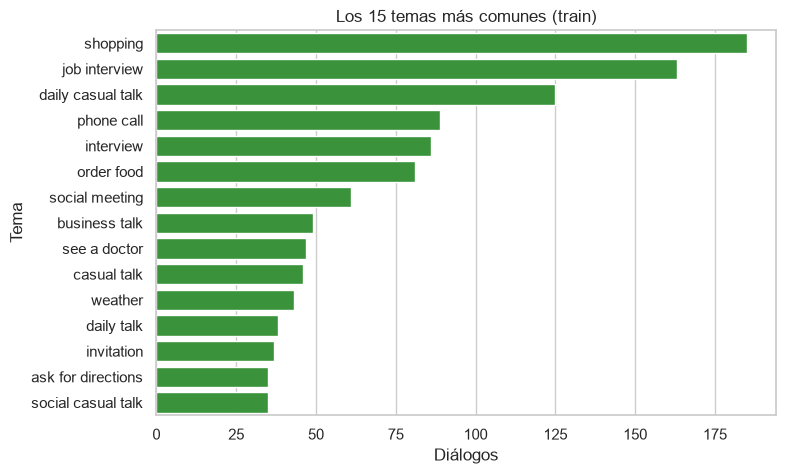

In [ ]:
# Temas más comunes en train
temas = train_sum["topic"].str.strip().str.lower().value_counts()
top = temas.head(15)
print(f"Temas distintos en train: {len(temas)}")
print(f"Los 15 más comunes cubren el {top.sum() / len(train_sum):.1%} de los diálogos")
print(f"Temas que aparecen una sola vez: {(temas == 1).sum()}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, ax=ax, color="tab:green")
ax.set(title="Los 15 temas más comunes (train)", xlabel="Diálogos", ylabel="Tema")
guardar(fig, "t3_temas")
plt.show()

Los temas son texto libre y muy variados: hay 7187 temas distintos en train y 5746 aparecen una sola vez. Los 15 más comunes (compras, entrevistas de trabajo, charla casual, llamadas por teléfono...) cubren solo el 9 % de los diálogos, así que ningún tema domina el dataset.

In [ ]:
# Un diálogo del test con sus 3 resúmenes. Los ids son test_<diálogo>_<1, 2 o 3>.
test_sum = df_sum["test"].copy()
test_sum["dialogo_id"] = test_sum["id"].str.rsplit("_", n=1).str[0]
grupos = test_sum.groupby("dialogo_id")
print(f"Diálogos en test: {grupos.ngroups}; resúmenes por diálogo: {grupos.size().value_counts().to_dict()}")
print(f"Grupos en los que las 3 filas tienen el mismo diálogo: {(grupos['dialogue'].nunique() == 1).mean():.0%}")
print(f"Grupos con los 3 temas distintos: {(grupos['topic'].nunique() == 3).sum()}")
textos_train = set(train_sum["dialogue"])
for split in ["validation", "test"]:
    print(f"Diálogos de {split} que también están en train: {df_sum[split]['dialogue'].isin(textos_train).sum()}")

ej_id = test_sum["dialogo_id"].drop_duplicates().sample(1, random_state=SEED).iloc[0]
grupo = grupos.get_group(ej_id)
print(f"\n{ej_id}\n")
mostrar_dialogo(grupo["dialogue"].iloc[0])
print()
for i, (_, r) in enumerate(grupo.iterrows(), 1):
    print(f"Resumen {i} ({r['tokens_resumen']} tokens, tema: {r['topic']}):")
    print(textwrap.fill(r["summary"], 110), end="\n\n")

Diálogos en test: 500; resúmenes por diálogo: {3: 500}
Grupos en los que las 3 filas tienen el mismo diálogo: 100%
Grupos con los 3 temas distintos: 350
Diálogos de validation que también están en train: 0
Diálogos de test que también están en train: 0

test_361

#Person1#: You're all set now?
#Person2#: Oh, thank you so much.
#Person1#: Really, it was nothing.
#Person2#: I really appreciated it.
#Person1#: I was happy to help.
#Person2#: It was so kind of you.
#Person1#: Don't mention it.
#Person2#: You're a real friend in need.

Resumen 1 (20 tokens, tema: gratitude):
#Person2# thanks #Person1# for #Person1#'s help.

Resumen 2 (18 tokens, tema: appreciation):
#Person2# appreciates for #Person1# 's kind help.

Resumen 3 (16 tokens, tema: appreciation):
#Person2# appreciates #Person1#'s help.



Los 500 diálogos del test tienen exactamente tres resúmenes cada uno, y las tres filas de cada grupo traen el mismo diálogo. Los resúmenes cuentan lo mismo con palabras distintas, como en este ejemplo ("thanks #Person1# for #Person1#'s help" frente a "appreciates #Person1#'s help"), y hasta el tema cambia: en 350 de los 500 diálogos los tres temas son distintos. Ningún diálogo de validación o de test aparece en train.

#### Qué implica para el entrenamiento

- max_source_length: uso 512 tokens para el diálogo, con lo que se corta el final del 1.49 % de los diálogos. Con 1024 solo se cortarían 12, pero cada batch que tenga uno de esos diálogos largos se vuelve mucho más caro. Si en la búsqueda de hiperparámetros veo que sobra tiempo, lo pruebo.
- max_target_length: 128 tokens para el resumen, que solo corta 13 resúmenes (0.09 %). Al generar uso el mismo límite; el resumen más largo del test tiene 104 tokens.
- Longitud de lo generado: el modelo aprende con los resúmenes de train, que son más largos que los del test, así que puede que genere resúmenes más largos que las referencias del test. Por eso reporto la longitud media de lo generado junto al ROUGE.
- Métrica: ROUGE-1, ROUGE-2, ROUGE-L y ROUGE-Lsum. ROUGE-1 y ROUGE-2 miden cuántas palabras y pares de palabras comparte el resumen generado con la referencia, y ROUGE-L mide la subsecuencia común más larga. En test genero una vez por diálogo (500) y comparo contra las tres referencias; el `rouge` de evaluate se queda con la que más se parece. Como tres personas resumen lo mismo con palabras distintas, comparar contra una sola referencia castigaría paráfrasis que están bien. Para ROUGE-Lsum separo las oraciones con saltos de línea.
- Etiquetas `#PersonN#`: no las agrego como tokens especiales. bart-base las parte en cuatro tokens que ya conoce, y el modelo puede aprender a copiarlas del diálogo.
- Validación: tiene 500 diálogos con una referencia cada uno. En la búsqueda de learning rate calculo ROUGE sobre 200 de ellos para no gastar mucho tiempo generando.

### 3.3 Búsqueda de hiperparámetros

### 3.4 Entrenamiento con la data completa

### 3.5 Evaluación del mejor modelo

## Conclusiones